# Modelo VGG16

In [104]:
from pathlib import Path

# Directorio raíz del proyecto
PROJECT_ROOT = Path.cwd()

# Datos locales
DATA_DIR = PROJECT_ROOT / "data"
IDRID_DIR = DATA_DIR / "IDRiD2"

# Archivos CSV
TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

# Directorios de imágenes
TRAIN_IMAGES_DIR = IDRID_DIR / "IDRiD" / "train" / "images"
TEST_IMAGES_DIR = IDRID_DIR / "IDRiD" / "test" / "images" 

# Comprobar estructura
required_paths = [
    TRAIN_CSV,
    VAL_CSV,
    TRAIN_IMAGES_DIR,
    TEST_IMAGES_DIR
]

missing_paths = [
    path for path in required_paths
    if not path.exists()
]

if missing_paths:
    print("Faltan los siguientes archivos/directorios locales:")
    
    for path in missing_paths:
        print(f" - {path}")
    
    raise FileNotFoundError(
        "Completa la estructura local indicada antes de continuar."
    )

print("Proyecto local:", PROJECT_ROOT)
print("Dataset:", IDRID_DIR)
print("Configuración local correcta.")

Proyecto local: c:\Users\lauri\Documents\PROYECTO_FINAL
Dataset: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2
Configuración local correcta.


IMPORTACIONES Y CONFIGURACIÓN 

In [105]:
pip install numpy pandas matplotlib scikit-learn tensorflow keras

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# IMPORTACIONES Y CONFIGURACION

In [106]:


import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import gc
import json
import math
import random
import shutil
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import mixed_precision

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

GPUS = tf.config.list_physical_devices("GPU")

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

if GPUS:
    mixed_precision.set_global_policy("mixed_float16")
else:
    mixed_precision.set_global_policy("float32")

print("TensorFlow:", tf.__version__)
print("GPU disponibles:", GPUS)
print("Política de precisión:", mixed_precision.global_policy())

TensorFlow: 2.21.0
GPU disponibles: []
Política de precisión: <DTypePolicy "float32">


# PARAMETROS GENERALES

In [107]:
CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# Ajuste automático según el hardware local.
BATCH_SIZE = 32 if GPUS else 8

HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 12

HEAD_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 3e-5

UNFREEZE_LAST_LAYERS = 40
DROPOUT_RATE = 0.35

# La caché guarda las imágenes redimensionadas en disco.
USE_DISK_CACHE = True

# Puede activarse si el entorno soporta XLA sin errores.
JIT_COMPILE = False

WORK_ROOT = PROJECT_ROOT

RUN_DIR = WORK_ROOT / "VGG16"
CACHE_DIR = RUN_DIR / "tf_cache"
LOG_DIR = RUN_DIR / "logs"

RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

HEAD_MODEL_PATH = RUN_DIR / "vgg16_head_best.keras"
FINETUNE_MODEL_PATH = RUN_DIR / "vgg16_finetuned_best.keras"
FINAL_MODEL_PATH = RUN_DIR / "vgg16_rdr_final.keras"

HISTORY_PATH = RUN_DIR / "historial_entrenamiento.csv"
METRICS_PATH = RUN_DIR / "metricas_validacion.json"
THRESHOLD_PATH = RUN_DIR / "umbral_clasificacion.json"
VALIDATION_PREDICTIONS_PATH = RUN_DIR / "predicciones_validacion.csv"
DASHBOARD_PATH = RUN_DIR / "dashboard_vgg16.html"

print("Directorio de resultados:", RUN_DIR)
print("Tamaño de imagen:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Directorio de resultados: c:\Users\lauri\Documents\PROYECTO_FINAL\VGG16
Tamaño de imagen: (224, 224)
Batch size: 8


# #Limpieza del manifiesto



In [108]:
import pandas as pd
from pathlib import Path

train_path = TRAIN_CSV
val_path = VAL_CSV

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

# ============================================================
# AUDITORÍA DEL SPLIT POR PACIENTE
# ============================================================

train_patients = set(train_df["patient_id"].astype(str))
val_patients = set(val_df["patient_id"].astype(str))

shared_patients = train_patients.intersection(val_patients)

print("===== AUDITORÍA POR PACIENTE =====")
print(f"Pacientes en TRAIN: {len(train_patients)}")
print(f"Pacientes en VALIDACIÓN: {len(val_patients)}")
print(f"Pacientes compartidos: {len(shared_patients)}")

if shared_patients:
    print("\n ERROR: Hay pacientes repartidos entre TRAIN y VALIDACIÓN.")
    print("Pacientes afectados:")
    print(sorted(shared_patients))

    raise ValueError(
        "El split no es seguro: existen pacientes "
        "presentes tanto en TRAIN como en VALIDACIÓN."
    )

else:
    print("\n CORRECTO: ningún paciente está compartido "
          "entre TRAIN y VALIDACIÓN.")

# Identificar originales: el nombre de imagen coincide con patient_id.
train_df["is_original"] = train_df["Image name"].astype(str).eq(
    train_df["patient_id"].astype(str)
)
val_df["is_original"] = val_df["Image name"].astype(str).eq(
    val_df["patient_id"].astype(str)
)

train_df["model_split"] = "train"
val_df["model_split"] = "val"

# Validación rigurosa: solo imágenes originales.
val_originals_df = val_df[val_df["is_original"]].copy()

# Manifiesto combinado recomendado para VGG16.
manifest_VGG16 = pd.concat(
    [train_df, val_originals_df],
    ignore_index=True
)


train_out = DATA_DIR / "train_split_VGG16.csv"
val_out = DATA_DIR / "val_split_VGG16.csv"
combined_out = DATA_DIR / "manifest_train_val_split_VGG16.csv"

train_df.to_csv(train_out, index=False)
val_originals_df.to_csv(val_out, index=False)
manifest_VGG16.to_csv(combined_out, index=False)

print(f"Train: {len(train_df)} filas, {train_df['patient_id'].nunique()} pacientes")
print(
    f"Validación original: {len(val_originals_df)} filas, "
    f"{val_originals_df['patient_id'].nunique()} pacientes"
)
print(f"Manifiesto combinado: {len(manifest_VGG16)} filas")

===== AUDITORÍA POR PACIENTE =====
Pacientes en TRAIN: 330
Pacientes en VALIDACIÓN: 83
Pacientes compartidos: 0

 CORRECTO: ningún paciente está compartido entre TRAIN y VALIDACIÓN.
Train: 2640 filas, 330 pacientes
Validación original: 83 filas, 83 pacientes
Manifiesto combinado: 2723 filas


# Configuracion General

In [109]:
import os
import gc
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
    
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


#config General

In [110]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# El determinismo estricto reduce el paralelismo de tf.data y puede ralentizar la GPU.
# Déjalo en False para entrenar rápido. Actívalo solo para reproducibilidad bit a bit.
STRICT_DETERMINISM = False
if STRICT_DETERMINISM:
    tf.config.experimental.enable_op_determinism()

# Precisión mixta solo cuando la GPU dispone de Tensor Cores (capacidad >= 7.0).
# En P100 o CPU, float32 suele ser igual o más rápido.
from tensorflow.keras import mixed_precision

gpus = tf.config.list_physical_devices("GPU")
compute_capability = None
if gpus:
    details = tf.config.experimental.get_device_details(gpus[0])
    compute_capability = details.get("compute_capability")

supports_tensor_cores = bool(
    gpus and (
        compute_capability is None or
        int(compute_capability[0]) >= 7
    )
)

DTYPE_POLICY = "mixed_float16" if supports_tensor_cores else "float32"
mixed_precision.set_global_policy(DTYPE_POLICY)

print("GPU detectada:", gpus)
print("Compute capability:", compute_capability)
print("Política numérica:", mixed_precision.global_policy().name)
print("Determinismo estricto:", STRICT_DETERMINISM)

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# 32 aprovecha bien T4/L4/A100 con mixed_float16. Si aparece OOM al abrir
# block4+block5, cambia únicamente a 16; no reduzcas IMG_SIZE.
BATCH_SIZE = 32 if supports_tensor_cores else 16
STEPS_PER_EXECUTION = 16

# "auto": RAM si cabe con margen; si no, caché en el SSD local de /content.
# No uses Google Drive como caché: su latencia es mucho mayor.
CACHE_MODE = "auto"          # "auto", "memory", "disk" o "none"
CACHE_RAM_FRACTION = 0.25
CACHE_DIR = Path("/data/tf_cache_vgg16")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# El benchmark queda apagado para evitar leer cientos de imágenes antes de entrenar.
RUN_PIPELINE_BENCHMARK = False

TRAIN_MANIFEST_PATH = "/data/train_split.csv"
VAL_MANIFEST_PATH = "/data/val_split.csv"

IMAGE_ROOTS = [
    DATA_DIR / "IDRiD2" / "IDRiD" / "train" / "images"
]

OUTPUT_DIR = Path("/data/modelos/VGG16")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
LOG_DIR = OUTPUT_DIR / "logs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "No referible",
    1: "Referible"
}


GPU detectada: []
Compute capability: None
Política numérica: float32
Determinismo estricto: False


# 3. Cargar y auditar los manifiestos

In [111]:
TRAIN_CSV = "data/train_split.csv"
VAL_CSV = "data/val_split.csv"

In [112]:
# 3. CARGAR Y AUDITAR LOS MANIFIESTOS

REQUIRED_COLUMNS = {"Image name", "binary_label", "patient_id"}

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)

for dataset_name, frame in [("train", train_df), ("val", val_df)]:
    missing = REQUIRED_COLUMNS - set(frame.columns)
    if missing:
        raise ValueError(
            f"Faltan columnas en {dataset_name}: {sorted(missing)}"
        )

    frame["Image name"] = frame["Image name"].astype(str).str.strip()
    frame["patient_id"] = frame["patient_id"].astype(str).str.strip()
    frame["binary_label"] = frame["binary_label"].astype(int)

    invalid = set(frame["binary_label"].unique()) - {0, 1}
    if invalid:
        raise ValueError(
            f"Etiquetas inválidas en {dataset_name}: {invalid}"
        )

patient_overlap = set(train_df["patient_id"]) & set(val_df["patient_id"])
if patient_overlap:
    raise ValueError(
        "Existe fuga de pacientes entre train y validación: "
        f"{sorted(patient_overlap)[:10]}"
    )

if EXCLUDE_VFLIP_FROM_TRAIN:
    previous_size = len(train_df)
    train_df = train_df[
        ~train_df["Image name"].str.endswith("_VFLIP", na=False)
    ].reset_index(drop=True)
    print("VFLIP excluidos:", previous_size - len(train_df))

print("Train:", train_df.shape)
print(train_df["binary_label"].value_counts().sort_index())
print("Pacientes train:", train_df["patient_id"].nunique())

print("\nValidación:", val_df.shape)
print(val_df["binary_label"].value_counts().sort_index())
print("Pacientes val:", val_df["patient_id"].nunique())

VFLIP excluidos: 330
Train: (2310, 9)
binary_label
0     861
1    1449
Name: count, dtype: int64
Pacientes train: 330

Validación: (83, 9)
binary_label
0    31
1    52
Name: count, dtype: int64
Pacientes val: 83


In [113]:
# ============================================================
# 4. RESOLVER RUTAS DE IMÁGENES SIN MEZCLAR TRAIN Y TEST
# ============================================================

from pathlib import Path


VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp",
}


# ============================================================
# CREAR ÍNDICE DE IMÁGENES
# ============================================================

def build_image_index(roots):

    index = {}
    duplicates = {}

    for root in roots:

        root = Path(root)

        if not root.exists():

            raise FileNotFoundError(
                f"No existe la carpeta:\n{root}"
            )

        if not root.is_dir():

            raise NotADirectoryError(
                f"La ruta no es una carpeta:\n{root}"
            )


        for path in root.rglob("*"):

            if not path.is_file():
                continue

            if path.suffix.lower() not in VALID_EXTENSIONS:
                continue


            # Usamos solo el nombre sin extensión
            # y en minúsculas para evitar diferencias
            # entre CSV y archivos reales.
            stem = (
                path.stem
                .strip()
                .lower()
            )


            absolute_path = str(
                path.resolve()
            )


            if (
                stem in index
                and
                index[stem] != absolute_path
            ):

                duplicates.setdefault(
                    stem,
                    [index[stem]]
                )

                duplicates[stem].append(
                    absolute_path
                )

            else:

                index[stem] = absolute_path


    # ========================================================
    # DETECTAR DUPLICADOS
    # ========================================================

    if duplicates:

        examples = list(
            duplicates.items()
        )[:10]


        details = "\n".join(

            f"{name}:\n"
            + "\n".join(
                f"   - {path}"
                for path in paths
            )

            for name, paths
            in examples
        )


        raise ValueError(

            "\nSe encontraron nombres de imagen duplicados "
            "dentro de las carpetas indexadas.\n\n"

            "Esto puede provocar fuga de datos o asignaciones "
            "ambiguas.\n\n"

            f"Ejemplos:\n{details}"
        )


    return index


# ============================================================
# ASIGNAR RUTAS A CADA MANIFIESTO
# ============================================================

def attach_paths(
    frame,
    image_index,
    dataset_name="dataset",
):

    result = frame.copy()


    # --------------------------------------------------------
    # Normalizar nombre de imagen del CSV
    # --------------------------------------------------------
    #
    # Esto funciona tanto si el CSV contiene:
    #
    # IDRiD_001
    #
    # como:
    #
    # IDRiD_001.jpg
    #
    # --------------------------------------------------------

    result["_image_key"] = (

        result["Image name"]
        .astype(str)
        .map(
            lambda value:
            Path(value.strip()).stem.lower()
        )
    )


    # --------------------------------------------------------
    # Buscar ruta
    # --------------------------------------------------------

    result["image_path"] = (
        result["_image_key"]
        .map(image_index)
    )


    # --------------------------------------------------------
    # Detectar imágenes no encontradas
    # --------------------------------------------------------

    missing_mask = (
        result["image_path"].isna()
    )


    missing = result.loc[
        missing_mask,
        "Image name",
    ].tolist()


    if missing:

        print("\n" + "=" * 80)

        print(
            f"IMÁGENES NO ENCONTRADAS EN {dataset_name.upper()}"
        )

        print("=" * 80)

        print(
            f"Total no encontradas: {len(missing)}"
        )

        print(
            "\nPrimeros ejemplos:"
        )


        for name in missing[:20]:

            print(
                f" - {name}"
            )


        raise FileNotFoundError(

            f"\nNo se pudieron resolver "
            f"{len(missing)} imágenes "
            f"del manifiesto {dataset_name}."
        )


    # Eliminar columna auxiliar
    result = result.drop(
        columns=["_image_key"]
    )


    return result


# ============================================================
# INDEXAR SOLO LAS IMÁGENES DE TRAIN
# ============================================================
#
# IMPORTANTE:
#
# train_df y val_df pertenecen al split de desarrollo,
# por lo tanto ambos deben buscarse únicamente dentro
# del conjunto de imágenes de entrenamiento.
#
# NO incluimos TEST_IMAGES_DIR aquí.
#
# ============================================================

TRAIN_IMAGE_ROOTS = [
    TRAIN_IMAGES_DIR
]


image_index = build_image_index(
    TRAIN_IMAGE_ROOTS
)


# ============================================================
# RESOLVER RUTAS PARA TRAIN Y VALIDACIÓN
# ============================================================

train_df = attach_paths(
    train_df,
    image_index,
    dataset_name="train",
)


val_df = attach_paths(
    val_df,
    image_index,
    dataset_name="validación",
)


# ============================================================
# COMPROBACIONES FINALES
# ============================================================

print("\n" + "=" * 80)

print(
    "RESOLUCIÓN DE RUTAS COMPLETADA"
)

print("=" * 80)


print(
    f"Imágenes indexadas: "
    f"{len(image_index):,}"
)


print(
    f"Rutas resueltas en TRAIN: "
    f"{train_df['image_path'].notna().sum():,}"
)


print(
    f"Rutas resueltas en VALIDACIÓN: "
    f"{val_df['image_path'].notna().sum():,}"
)


print(
    "\nTodas las rutas fueron resueltas "
    "sin utilizar imágenes de TEST."
)


print("=" * 80)


RESOLUCIÓN DE RUTAS COMPLETADA
Imágenes indexadas: 3,304
Rutas resueltas en TRAIN: 2,310
Rutas resueltas en VALIDACIÓN: 83

Todas las rutas fueron resueltas sin utilizar imágenes de TEST.


In [114]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Cargar el manifiesto con las etiquetas disponibles
manifest = pd.read_csv(TRAIN_MANIFEST_PATH)

# Identificar imágenes originales disponibles
manifest["Image name"] = manifest["Image name"].astype(str).str.strip()
manifest["patient_id"] = manifest["patient_id"].astype(str).str.strip()

manifest["is_original"] = (
    manifest["Image name"] == manifest["patient_id"]
)

originals = (
    manifest[manifest["is_original"]]
    .drop_duplicates(subset=["Image name"])
    .reset_index(drop=True)
)

print("Imágenes originales etiquetadas:", len(originals))

# Separar por paciente: 80 % entrenamiento, 20 % validación
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(originals, groups=originals["patient_id"])
)

train_raw = originals.iloc[train_idx].copy().reset_index(drop=True)
val_raw = originals.iloc[val_idx].copy().reset_index(drop=True)

# Guardar los nuevos manifiestos
train_raw.to_csv(TRAIN_MANIFEST_PATH, index=False)
val_raw.to_csv(VAL_MANIFEST_PATH, index=False)

print("Entrenamiento:", len(train_raw))
print("Validación:", len(val_raw))

Imágenes originales etiquetadas: 330
Entrenamiento: 264
Validación: 66


In [115]:
import pandas as pd
from pathlib import Path

train_path = TRAIN_CSV
val_path = VAL_CSV

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

# ============================================================
# AUDITORÍA DEL SPLIT POR PACIENTE
# ============================================================

train_patients = set(train_df["patient_id"].astype(str))
val_patients = set(val_df["patient_id"].astype(str))

shared_patients = train_patients.intersection(val_patients)

print("===== AUDITORÍA POR PACIENTE =====")
print(f"Pacientes en TRAIN: {len(train_patients)}")
print(f"Pacientes en VALIDACIÓN: {len(val_patients)}")
print(f"Pacientes compartidos: {len(shared_patients)}")

if shared_patients:
    print("\n ERROR: Hay pacientes repartidos entre TRAIN y VALIDACIÓN.")
    print("Pacientes afectados:")
    print(sorted(shared_patients))

    raise ValueError(
        "El split no es seguro: existen pacientes "
        "presentes tanto en TRAIN como en VALIDACIÓN."
    )

else:
    print("\n CORRECTO: ningún paciente está compartido "
          "entre TRAIN y VALIDACIÓN.")

# Identificar originales: el nombre de imagen coincide con patient_id.
train_df["is_original"] = train_df["Image name"].astype(str).eq(
    train_df["patient_id"].astype(str)
)
val_df["is_original"] = val_df["Image name"].astype(str).eq(
    val_df["patient_id"].astype(str)
)

train_df["model_split"] = "train"
val_df["model_split"] = "val"

# Validación rigurosa: solo imágenes originales.
val_originals_df = val_df[val_df["is_original"]].copy()

# Manifiesto combinado recomendado para VGG16.
manifest_VGG16 = pd.concat(
    [train_df, val_originals_df],
    ignore_index=True
)

train_out = DATA_DIR / "train_split_VGG16.csv"
val_out = DATA_DIR / "val_split_VGG16.csv"
combined_out = DATA_DIR / "manifest_train_val_split_VGG16.csv"

train_df.to_csv(train_out, index=False)
val_originals_df.to_csv(val_out, index=False)
manifest_EfficientNetB0.to_csv(combined_out, index=False)

print(f"Train: {len(train_df)} filas, {train_df['patient_id'].nunique()} pacientes")
print(
    f"Validación original: {len(val_originals_df)} filas, "
    f"{val_originals_df['patient_id'].nunique()} pacientes"
)
print(f"Manifiesto combinado: {len(manifest_EfficientNetB0)} filas")

===== AUDITORÍA POR PACIENTE =====
Pacientes en TRAIN: 330
Pacientes en VALIDACIÓN: 83
Pacientes compartidos: 0

 CORRECTO: ningún paciente está compartido entre TRAIN y VALIDACIÓN.
Train: 2640 filas, 330 pacientes
Validación original: 83 filas, 83 pacientes
Manifiesto combinado: 2723 filas


#INDICE UNICO DE IMAGENES

In [116]:


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
}

IMAGE_ROOTS = [
    TRAIN_IMAGES_DIR,
    TEST_IMAGES_DIR,
]

IMAGE_ROOTS = [
    root for root in IMAGE_ROOTS
    if root.exists()
]


def build_image_index(roots):
    """
    Recorre todos los directorios una sola vez.

    Retorna:
        {
            "idrid_001": [ruta1, ruta2],
            "idrid_001_r8": [ruta],
            ...
        }
    """
    image_index = {}
    total_images = 0

    for root in roots:
        print("Indexando:", root)

        for directory, _, filenames in os.walk(root):
            for filename in filenames:
                suffix = Path(filename).suffix.lower()

                if suffix not in IMAGE_EXTENSIONS:
                    continue

                full_path = Path(directory) / filename
                image_key = full_path.stem.lower().strip()

                image_index.setdefault(image_key, []).append(
                    str(full_path)
                )

                total_images += 1

    print("\nTotal de archivos de imagen encontrados:", total_images)
    print("Nombres únicos:", len(image_index))

    return image_index


image_index = build_image_index(IMAGE_ROOTS)

Indexando: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\train\images
Indexando: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\test\images

Total de archivos de imagen encontrados: 4128
Nombres únicos: 3304


#ASIGNAR PATH A LOS MANIFIESTOS

In [117]:


def image_path_score(path):
    """
    Si existe el mismo nombre en Training Set y Testing Set,
    prioriza la imagen procedente del conjunto de entrenamiento.
    """
    normalized = str(path).replace("\\", "/").lower()

    score = 0

    if "/train/" in normalized:
        score += 200

    if "training set" in normalized:
        score += 200

    if "/training/" in normalized:
        score += 150

    if "/images/" in normalized:
        score += 20

    if "augmented" in normalized:
        score += 500

    if "/test/" in normalized:
        score -= 200

    if "testing set" in normalized:
        score -= 200

    return score


def resolve_image_path(image_name):
    image_key = Path(str(image_name)).stem.lower().strip()
    candidates = image_index.get(image_key, [])

    if not candidates:
        return None

    return max(
        candidates,
        key=lambda path: (
            image_path_score(path),
            -len(path),
        ),
    )


train_df["image_path"] = train_df["Image name"].map(
    resolve_image_path
)

val_df["image_path"] = val_df["Image name"].map(
    resolve_image_path
)

missing_train = train_df[
    train_df["image_path"].isna()
]

missing_val = val_df[
    val_df["image_path"].isna()
]

print("Imágenes faltantes en entrenamiento:", len(missing_train))
print("Imágenes faltantes en validación:", len(missing_val))

if len(missing_train) > 0:
    display(missing_train[["Image name"]].head(20))

if len(missing_val) > 0:
    display(missing_val[["Image name"]].head(20))

if len(missing_train) > 0 or len(missing_val) > 0:
    raise FileNotFoundError(
        "No fue posible localizar todas las imágenes. "
        "Revisa que el dataset de ENLACE-DATA esté agregado "
        "en la sección Input del notebook."
    )

# Verificar que no se esté utilizando el mismo archivo en ambos conjuntos.
shared_paths = set(train_df["image_path"]).intersection(
    set(val_df["image_path"])
)

if shared_paths:
    raise ValueError(
        f"Hay {len(shared_paths)} archivos compartidos entre "
        "entrenamiento y validación."
    )

print("\nEjemplos de rutas resueltas:")
display(
    train_df[
        ["Image name", "binary_label", "image_path"]
    ].head(5)
)

print(train_df["image_path"].head(5))
valor = train_df["image_path"].head(20).tolist()

# Abre el archivo en modo escritura ('w')
with open("prueba.txt", "w", encoding="utf-8") as archivo:
    archivo.write("\n".join(str(path) for path in valor))


Imágenes faltantes en entrenamiento: 0
Imágenes faltantes en validación: 0

Ejemplos de rutas resueltas:


,Image name,binary_label,image_path
0,IDRiD_001,1,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
1,IDRiD_002,1,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
2,IDRiD_004,1,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
3,IDRiD_005,1,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
4,IDRiD_006,1,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...


0    c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
1    c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
2    c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
3    c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
4    c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
Name: image_path, dtype: str


#COMPROBACION RAPIDA DE CODIFICACIÓN

In [118]:


sample_paths = pd.concat(
    [
        train_df["image_path"].sample(
            min(8, len(train_df)),
            random_state=SEED,
        ),
        val_df["image_path"].sample(
            min(4, len(val_df)),
            random_state=SEED,
        ),
    ],
    ignore_index=True,
)

decode_errors = []

for image_path in sample_paths:
    try:
        image_bytes = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False,
        )

        if image.shape[-1] != 3:
            decode_errors.append(image_path)

    except Exception as error:
        decode_errors.append(
            (image_path, str(error))
        )

if decode_errors:
    print("Archivos con problemas:")
    print(decode_errors)
else:
    print(
        f"Comprobación exitosa: "
        f"{len(sample_paths)} imágenes decodificadas."
    )

Comprobación exitosa: 12 imágenes decodificadas.


In [119]:
# ============================================================
# DIAGNÓSTICO DE DISTRIBUCIÓN DE CLASES
# VGG16 / EfficientNetB0
# ============================================================

import pandas as pd

print("=" * 55)
print("AUDITORÍA DE ENTRENAMIENTO Y VALIDACIÓN")
print("=" * 55)

for nombre, df in [
    ("ENTRENAMIENTO", train_df),
    ("VALIDACIÓN", val_df),
]:

    print(f"\n===== {nombre} =====")

    print("Total de imágenes:", len(df))

    print("\nDistribución de clases:")
    print(
        df["binary_label"]
        .value_counts()
        .sort_index()
    )

    # Verificar pacientes
    if "patient_id" in df.columns:

        print(
            "\nPacientes únicos:",
            df["patient_id"].nunique()
        )

        print("\nImágenes por paciente:")
        print(
            df.groupby("patient_id")
            .size()
            .value_counts()
            .sort_index()
        )

    # Verificar imágenes originales
    if "is_original" in df.columns:

        print("\nOriginales y versiones adicionales:")
        print(
            df["is_original"]
            .value_counts(dropna=False)
        )

    # Verificar nombres
    if "Image name" in df.columns:

        print("\nPrimeras 5 imágenes:")
        print(
            df["Image name"].head(5).to_string(index=False)
        )

# ============================================================
# COMPROBAR FUGA ENTRE PACIENTES
# ============================================================

if (
    "patient_id" in train_df.columns
    and "patient_id" in val_df.columns
):

    train_patients = set(
        train_df["patient_id"].astype(str)
    )

    val_patients = set(
        val_df["patient_id"].astype(str)
    )

    shared = train_patients.intersection(
        val_patients
    )

    print("\n===== CONTROL DE FUGA =====")

    print("Pacientes compartidos:", len(shared))

    if shared:
        print("ALERTA: hay pacientes compartidos.")
        print(sorted(shared)[:10])
    else:
        print("CORRECTO: no hay pacientes compartidos.")

AUDITORÍA DE ENTRENAMIENTO Y VALIDACIÓN

===== ENTRENAMIENTO =====
Total de imágenes: 2640

Distribución de clases:
binary_label
0     984
1    1656
Name: count, dtype: int64

Pacientes únicos: 330

Imágenes por paciente:
8    330
Name: count, dtype: int64

Originales y versiones adicionales:
is_original
False    2310
True      330
Name: count, dtype: int64

Primeras 5 imágenes:
IDRiD_001
IDRiD_002
IDRiD_004
IDRiD_005
IDRiD_006

===== VALIDACIÓN =====
Total de imágenes: 83

Distribución de clases:
binary_label
0    31
1    52
Name: count, dtype: int64

Pacientes únicos: 83

Imágenes por paciente:
1    83
Name: count, dtype: int64

Originales y versiones adicionales:
is_original
True    83
Name: count, dtype: int64

Primeras 5 imágenes:
IDRiD_003
IDRiD_012
IDRiD_028
IDRiD_029
IDRiD_031

===== CONTROL DE FUGA =====
Pacientes compartidos: 0
CORRECTO: no hay pacientes compartidos.


In [120]:
print("===== VALIDACIÓN VGG16 =====")

print("Total de imágenes:", len(val_df))

print("Pacientes únicos:",
      val_df["patient_id"].nunique())

print("\nImágenes por paciente:")
print(val_df.groupby("patient_id").size().value_counts())

print("\nImágenes originales:")
print(val_df["is_original"].value_counts())

===== VALIDACIÓN VGG16 =====
Total de imágenes: 83
Pacientes únicos: 83

Imágenes por paciente:
1    83
Name: count, dtype: int64

Imágenes originales:
is_original
True    83
Name: count, dtype: int64


,Entrenamiento,Validación
No referible,984,31
Referible,1656,52


Pesos de clase: {0: 1.3414634146341464, 1: 0.7971014492753623}


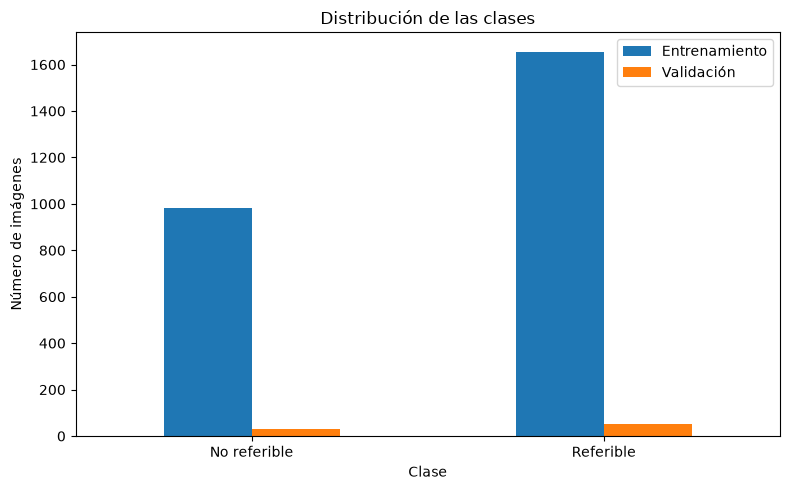

In [121]:

train_distribution = (
    train_df["binary_label"]
    .value_counts()
    .sort_index()
)

val_distribution = (
    val_df["binary_label"]
    .value_counts()
    .sort_index()
)

distribution_df = pd.DataFrame({
    "Entrenamiento": train_distribution,
    "Validación": val_distribution,
}).fillna(0).astype(int)

distribution_df.index = [
    CLASS_NAMES[int(label)]
    for label in distribution_df.index
]

display(distribution_df)

classes = np.array([0, 1], dtype=np.int32)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["binary_label"].to_numpy(),
)

CLASS_WEIGHT = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Pesos de clase:", CLASS_WEIGHT)

distribution_df.plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribución de las clases",
)

plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

PIPLENE

In [122]:


AUTOTUNE = tf.data.AUTOTUNE


def dataset_fingerprint(dataframe):
    content = "\n".join(
        dataframe["image_path"].astype(str)
        + "|"
        + dataframe["binary_label"].astype(str)
    )

    return hashlib.md5(
        content.encode("utf-8")
    ).hexdigest()[:12]


def decode_and_resize(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    # Mantiene la proporción de la retina sin deformarla.
    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_HEIGHT,
        target_width=IMG_WIDTH,
        method="bilinear",
        antialias=True,
    )

    image = tf.clip_by_value(
        image,
        clip_value_min=0.0,
        clip_value_max=255.0,
    )

    # Cachear uint8 consume aproximadamente 4 veces menos espacio.
    image = tf.cast(image, tf.uint8)
    label = tf.cast(label, tf.float32)

    return image, label


def make_dataset(
    dataframe,
    training=False,
    cache_name=None,
):
    paths = dataframe["image_path"].astype(str).to_numpy()
    labels = dataframe["binary_label"].astype(np.float32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        decode_and_resize,
        num_parallel_calls=AUTOTUNE,
        deterministic=not training,
    )

    if USE_DISK_CACHE and cache_name is not None:
        fingerprint = dataset_fingerprint(dataframe)

        cache_path = CACHE_DIR / (
            f"{cache_name}_{fingerprint}_"
            f"{IMG_HEIGHT}x{IMG_WIDTH}"
        )

        dataset = dataset.cache(str(cache_path))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    )

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = make_dataset(
    train_df,
    training=True,
    cache_name="train",
)

val_ds = make_dataset(
    val_df,
    training=False,
    cache_name="val",
)

print("Pipeline de entrenamiento:", train_ds)
print("Pipeline de validación:", val_ds)

Pipeline de entrenamiento: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>
Pipeline de validación: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>


#REVISION DE UN SOLO LOTE

Forma de las imágenes: (16, 224, 224, 3)
Tipo de dato: <dtype: 'uint8'>
Forma de etiquetas: (16,)
Rango: 0 254


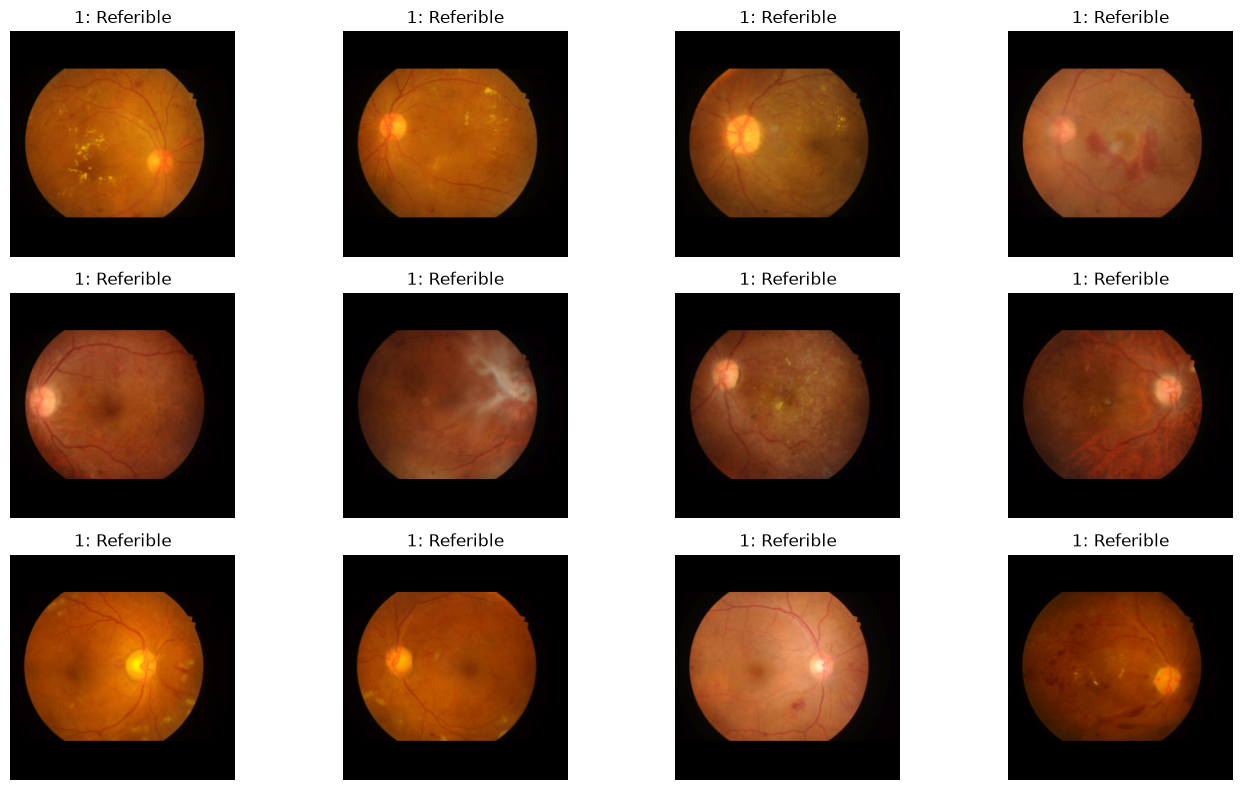

In [123]:
# Creamos un minidataset temporal sin caché ni mezcla para que la revisión sea instantánea
quick_check_ds = make_dataset(
    train_df.head(BATCH_SIZE),
    training=False,
    cache_name=None,
)

batch_images, batch_labels = next(
    iter(quick_check_ds.take(1))
)

print("Forma de las imágenes:", batch_images.shape)
print("Tipo de dato:", batch_images.dtype)
print("Forma de etiquetas:", batch_labels.shape)
print("Rango:", batch_images.numpy().min(), batch_images.numpy().max())

plt.figure(figsize=(14, 8))

images_to_show = min(12, len(batch_images))

for index in range(images_to_show):
    plt.subplot(3, 4, index + 1)

    plt.imshow(
        batch_images[index].numpy().astype(np.uint8)
    )

    label = int(batch_labels[index].numpy())

    plt.title(
        f"{label}: {CLASS_NAMES[label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

#Identificacionde imagenes originales y aumentadas

In [124]:
def add_manifest_metadata(dataframe, split_name):
    dataframe = dataframe.copy()

    dataframe["Image name"] = (
        dataframe["Image name"].astype(str).str.strip()
    )
    dataframe["patient_id"] = (
        dataframe["patient_id"].astype(str).str.strip()
    )
    dataframe["binary_label"] = dataframe["binary_label"].astype(int)
    dataframe["is_original"] = (
        dataframe["Image name"] == dataframe["patient_id"]
    )
    dataframe["model_split"] = split_name

    return dataframe


train_df = add_manifest_metadata(train_raw, "train")
val_complete_df = add_manifest_metadata(val_raw, "val")

val_df = val_complete_df.copy().reset_index(drop=True)

print("Train:", len(train_df))
print("Validación:", len(val_df))

Train: 264
Validación: 66


# Usar originales en la validacion

In [125]:
val_df = (
    val_complete_df[
        val_complete_df["is_original"]
    ]
    .copy()
    .reset_index(drop=True)
)

train_df = train_df.reset_index(drop=True)

print("Filas utilizadas en train:", len(train_df))
print("Filas utilizadas en validación:", len(val_df))

print("\nDistribución de train:")
print(
    train_df["binary_label"]
    .value_counts()
    .sort_index()
)

print("\nDistribución de validación:")
print(
    val_df["binary_label"]
    .value_counts()
    .sort_index()
)

Filas utilizadas en train: 264
Filas utilizadas en validación: 66

Distribución de train:
binary_label
0     98
1    166
Name: count, dtype: int64

Distribución de validación:
binary_label
0    25
1    41
Name: count, dtype: int64


# Comprobar consistencia por paciente

In [126]:
columns_to_check = [
    "binary_label",
    "Retinopathy grade",
    "Risk of macular edema",
    "class"
]

for column in columns_to_check:
    inconsistent_train = (
        train_df
        .groupby("patient_id")[column]
        .nunique()
        .gt(1)
        .sum()
    )

    inconsistent_val = (
        val_complete_df
        .groupby("patient_id")[column]
        .nunique()
        .gt(1)
        .sum()
    )

    print(
        f"{column}: "
        f"train={inconsistent_train}, "
        f"val={inconsistent_val}"
    )

    if inconsistent_train > 0 or inconsistent_val > 0:
        raise ValueError(
            f"Se encontraron inconsistencias en {column}."
        )

binary_label: train=0, val=0
Retinopathy grade: train=0, val=0
Risk of macular edema: train=0, val=0
class: train=0, val=0


asignacion de rutas


In [127]:
def assign_image_paths(dataframe, image_index):
    dataframe = dataframe.copy()

    dataframe["image_path"] = (
        dataframe["Image name"]
        .str.lower()
        .str.strip()
        .map(image_index)
)

    missing = dataframe[
        dataframe["image_path"].isna()
    ]

    if len(missing) > 0:
        print("Imágenes faltantes:", len(missing))

        display(
            missing[
                [
                    "Image name",
                    "patient_id",
                    "model_split"
                ]
            ].head(30)
        )

        raise FileNotFoundError(
            "No se encontraron todas las imágenes. "
            "Revisa IMAGE_ROOTS y las extensiones."
        )

    return dataframe


train_df = assign_image_paths(
    train_df,
    image_index
)

val_df = assign_image_paths(
    val_df,
    image_index
)

print("Todas las imágenes fueron encontradas.")

Todas las imágenes fueron encontradas.


In [128]:
print(train_df["image_path"].iloc[0])
print(type(train_df["image_path"].iloc[0]))

['c:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\data\\IDRiD2\\IDRiD\\train\\images\\IDRiD_001.jpg', 'c:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\data\\IDRiD2\\IDRiD\\test\\images\\IDRiD_001.jpg']
<class 'list'>


In [129]:
print(train_df["image_path"].iloc[0])
print(type(train_df["image_path"].iloc[0]))

['c:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\data\\IDRiD2\\IDRiD\\train\\images\\IDRiD_001.jpg', 'c:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\data\\IDRiD2\\IDRiD\\test\\images\\IDRiD_001.jpg']
<class 'list'>


# Visualizar muestras

In [130]:
def assign_image_paths(dataframe, image_index):
    dataframe = dataframe.copy()

    dataframe["image_path"] = (
        dataframe["Image name"]
        .str.lower()
        .str.strip()
        .map(image_index)
    )

    # Convertir las listas en rutas individuales
    dataframe["image_path"] = dataframe["image_path"].apply(
        lambda paths: paths[0]
        if isinstance(paths, list) and len(paths) > 0
        else paths
    )

    missing = dataframe[
        dataframe["image_path"].isna()
    ]

    if len(missing) > 0:
        print("Imágenes faltantes:", len(missing))

        display(
            missing[
                ["Image name", "patient_id", "model_split"]
            ].head(30)
        )

        raise FileNotFoundError(
            "No se encontraron todas las imágenes."
        )

    return dataframe

In [131]:
TRAIN_IMAGE_ROOTS = [
    DATA_DIR / "IDRiD2" / "IDRiD" / "train" / "images"
]

TEST_IMAGE_ROOTS = [
    DATA_DIR / "IDRiD2" / "IDRiD" / "test" / "images"
]

train_image_index = build_image_index(TRAIN_IMAGE_ROOTS)
test_image_index = build_image_index(TEST_IMAGE_ROOTS)

Indexando: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\train\images

Total de archivos de imagen encontrados: 3304
Nombres únicos: 3304
Indexando: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\test\images

Total de archivos de imagen encontrados: 824
Nombres únicos: 824


In [132]:
train_df = assign_image_paths(
    train_df,
    train_image_index
)

val_df = assign_image_paths(
    val_df,
    train_image_index
)

In [133]:
print(train_df["image_path"].iloc[0])
print(type(train_df["image_path"].iloc[0]))

c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\train\images\IDRiD_001.jpg
<class 'str'>


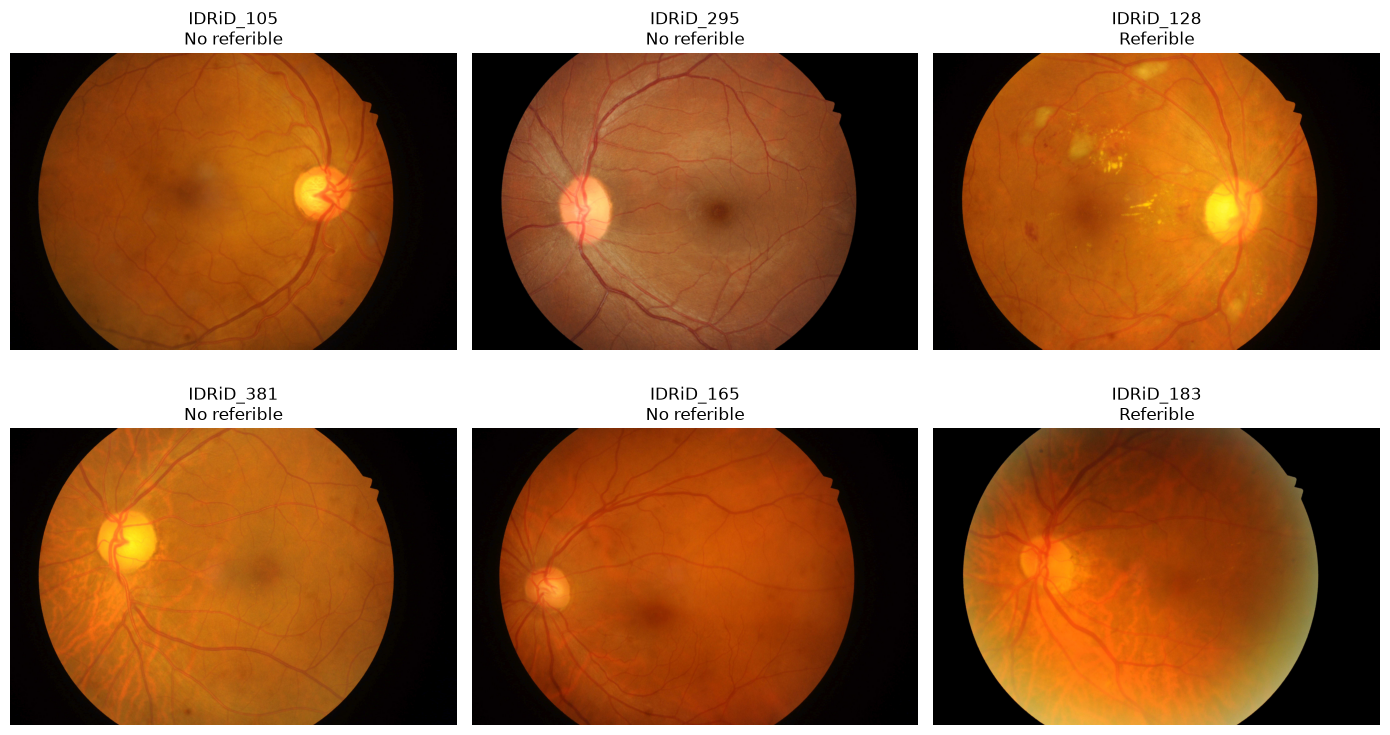

In [134]:
def show_examples(dataframe, n=6):
    sample = dataframe.sample(
        n=min(n, len(dataframe)),
        random_state=SEED
    )

    plt.figure(figsize=(14, 8))

    for position, (_, row) in enumerate(
        sample.iterrows(),
        start=1
    ):
        image = keras.utils.load_img(
            row["image_path"]
        )

        plt.subplot(2, 3, position)
        plt.imshow(image)

        label_name = CLASS_NAMES[
            int(row["binary_label"])
        ]

        plt.title(
            f'{row["Image name"]}\n'
            f'{label_name}'
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_examples(train_df)

In [135]:
train_df.head(10)

,Image name,Retinopathy grade,Risk of macular edema,class,Captions,binary_label,patient_id,is_original,model_split,image_path
0,IDRiD_001,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_001,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
1,IDRiD_002,3,2,Clinically_Significant_Macular_Edema,Severe nonproliferative diabetic retinopathy w...,1,IDRiD_002,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
2,IDRiD_004,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_004,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
3,IDRiD_006,4,1,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_006,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
4,IDRiD_008,4,2,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_008,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
5,IDRiD_010,4,1,Severe_PDR,Proliferative diabetic retinopathy with widesp...,1,IDRiD_010,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
6,IDRiD_013,3,0,Severe_PDR,Fundoscopic examination reveals severe diabeti...,1,IDRiD_013,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
7,IDRiD_014,4,2,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_014,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
8,IDRiD_015,4,2,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_015,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
9,IDRiD_016,2,2,Clinically_Significant_Macular_Edema,Moderate nonproliferative diabetic retinopathy...,1,IDRiD_016,True,train,c:\Users\lauri\Documents\PROYECTO_FINAL\data\I...


# Crear los datasets de TensorFlow

Las imágenes de entrenamiento ya incluyen transformaciones geométricas precomputadas, por lo que se conserva solamente un contraste ligero en línea.

La primera época todavía debe leer y decodificar los JPEG originales. Desde la segunda época, la caché evita repetir la parte costosa. La prueba de lote utiliza un dataset separado sin caché para no dejar una caché incompleta.


In [136]:
AUTOTUNE = tf.data.AUTOTUNE

photometric_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        layers.RandomRotation(factor=0.15, seed=SEED),
        layers.RandomZoom(height_factor=0.1, width_factor=0.1, seed=SEED),
        layers.RandomContrast(factor=0.1, seed=SEED)
    ],
    name="strong_data_augmentation"
)

# La rama rápida usa el decodificador JPEG específico. tf.io.decode_image es
# genérico, pero tiene más sobrecarga y ofrece menos información estática al grafo.
all_extensions = {
    Path(path).suffix.lower()
    for path in pd.concat(
        [train_df["image_path"], val_df["image_path"]],
        ignore_index=True
    ).astype(str)
}
ALL_IMAGES_ARE_JPEG = all_extensions.issubset({".jpg", ".jpeg"})

print("Extensiones encontradas:", sorted(all_extensions))
print("Decodificador rápido JPEG:", ALL_IMAGES_ARE_JPEG)


Extensiones encontradas: ['.jpg']
Decodificador rápido JPEG: True


In [137]:
def decode_and_resize(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    if ALL_IMAGES_ARE_JPEG:
        image = tf.io.decode_jpeg(
            image_bytes,
            channels=3
        )
    else:
        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )
        image.set_shape([None, None, 3])

    # Mantener float32 durante el resize conserva la interpolación y el antialias.
    image = tf.cast(image, tf.float32)
    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_HEIGHT,
        target_width=IMG_WIDTH,
        method="bilinear",
        antialias=True
    )

    label = tf.cast(label, tf.float32)
    return image, label


def prepare_training_image(image, label):
    image = photometric_augmentation(image, training=True)
    image = preprocess_input(image)
    return image, label


def prepare_evaluation_image(image, label):
    image = preprocess_input(image)
    return image, label


In [138]:
import hashlib
import psutil


def estimate_resized_cache_gib(number_of_images):
    bytes_per_image = IMG_HEIGHT * IMG_WIDTH * 3 * np.dtype(np.float32).itemsize
    return (number_of_images * bytes_per_image) / (1024 ** 3)


def dataset_signature(image_paths, labels):
    # Evita reutilizar una caché de otro split o de etiquetas modificadas.
    digest = hashlib.sha1()
    digest.update(f"{IMG_HEIGHT}x{IMG_WIDTH}".encode())
    for path, label in zip(image_paths, labels):
        digest.update(str(path).encode())
        digest.update(str(float(label)).encode())
    return digest.hexdigest()[:12]


def resolve_cache_mode(number_of_images, requested_mode):
    requested_mode = requested_mode.lower()
    if requested_mode != "auto":
        return requested_mode

    estimated_gib = estimate_resized_cache_gib(number_of_images)
    available_gib = psutil.virtual_memory().available / (1024 ** 3)

    return (
        "memory"
        if estimated_gib <= available_gib * CACHE_RAM_FRACTION
        else "disk"
    )


def make_dataset(
    dataframe,
    training=False,
    cache=True,
    batch_size=BATCH_SIZE,
    dataset_name=None
):
    image_paths = dataframe["image_path"].astype(str).to_numpy()
    labels = dataframe["binary_label"].astype(np.float32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))

    options = tf.data.Options()
    options.autotune.enabled = True
    # Entrenamiento no requiere mantener el orden de finalización de los workers.
    options.experimental_deterministic = not training
    dataset = dataset.with_options(options)

    dataset = dataset.map(
        decode_and_resize,
        num_parallel_calls=AUTOTUNE,
        deterministic=not training
    )

    effective_cache_mode = "none"
    if cache:
        effective_cache_mode = resolve_cache_mode(len(dataframe), CACHE_MODE)

        if effective_cache_mode == "memory":
            dataset = dataset.cache()
        elif effective_cache_mode == "disk":
            signature = dataset_signature(image_paths, labels)
            split_name = dataset_name or ("train" if training else "eval")
            cache_path = CACHE_DIR / f"{split_name}_{signature}.cache"
            dataset = dataset.cache(str(cache_path))
        elif effective_cache_mode != "none":
            raise ValueError(
                "CACHE_MODE debe ser: auto, memory, disk o none."
            )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        dataset = dataset.map(
            prepare_training_image,
            num_parallel_calls=AUTOTUNE,
            deterministic=False
        )
    else:
        dataset = dataset.map(
            prepare_evaluation_image,
            num_parallel_calls=AUTOTUNE,
            deterministic=True
        )

    dataset = dataset.batch(
        batch_size,
        drop_remainder=False
    )
    dataset = dataset.prefetch(AUTOTUNE)

    estimated_gib = estimate_resized_cache_gib(len(dataframe))
    print(
        f"{dataset_name or 'dataset'}: {len(dataframe)} imágenes | "
        f"batch={batch_size} | caché={effective_cache_mode} | "
        f"estimación={estimated_gib:.2f} GiB"
    )
    return dataset


train_ds = make_dataset(
    train_df,
    training=True,
    cache=True,
    dataset_name="train"
)

val_ds = make_dataset(
    val_df,
    training=False,
    cache=True,
    dataset_name="val"
)


train: 264 imágenes | batch=16 | caché=memory | estimación=0.15 GiB
val: 66 imágenes | batch=16 | caché=memory | estimación=0.04 GiB


#### Comprobar un lote sin contaminar la caché principal

No se debe ejecutar `train_ds.take(k)` para hacer benchmarks parciales cuando hay un `cache()` anterior: una iteración incompleta hace que TensorFlow descarte la caché parcial. Esta prueba usa solo cuatro imágenes y `cache=False`.


In [139]:
preview_size = min(4, len(train_df))
preview_df = train_df.sample(
    n=preview_size,
    random_state=SEED
).reset_index(drop=True)

preview_ds = make_dataset(
    preview_df,
    training=False,
    cache=False,
    batch_size=preview_size,
    dataset_name="preview"
)

images, labels_batch = next(iter(preview_ds))

print("Imágenes:", images.shape)
print("Etiquetas:", labels_batch.shape)
print("Dtype de imágenes:", images.dtype)
print("Dtype de etiquetas:", labels_batch.dtype)
print("Valores:", labels_batch.numpy())


preview: 4 imágenes | batch=4 | caché=none | estimación=0.00 GiB
Imágenes: (4, 224, 224, 3)
Etiquetas: (4,)
Dtype de imágenes: <dtype: 'float32'>
Dtype de etiquetas: <dtype: 'float32'>
Valores: [0. 0. 1. 0.]


In [140]:
import time

if RUN_PIPELINE_BENCHMARK:
    benchmark_size = min(128, len(train_df))
    benchmark_df = train_df.sample(
        n=benchmark_size,
        random_state=SEED
    ).reset_index(drop=True)

    benchmark_ds = make_dataset(
        benchmark_df,
        training=False,
        cache=False,
        batch_size=BATCH_SIZE,
        dataset_name="benchmark"
    )

    start_time = time.perf_counter()
    processed = 0

    for images_batch, _ in benchmark_ds:
        processed += int(images_batch.shape[0])

    elapsed = time.perf_counter() - start_time
    print(f"Procesadas: {processed} imágenes")
    print(f"Tiempo: {elapsed:.2f} s")
    print(f"Rendimiento de entrada: {processed / elapsed:.2f} imágenes/s")
else:
    print(
        "Benchmark omitido. Cambia RUN_PIPELINE_BENCHMARK=True "
        "solo cuando necesites medir el pipeline."
    )


Benchmark omitido. Cambia RUN_PIPELINE_BENCHMARK=True solo cuando necesites medir el pipeline.


# Calcular pesos de la Clase

In [141]:
class_counts = (
    train_df["binary_label"]
    .value_counts()
    .sort_index()
)

number_of_samples = len(train_df)
number_of_classes = 2

class_weight = {
    int(class_id): (
        number_of_samples /
        (number_of_classes * count)
    )
    for class_id, count in class_counts.items()
}

print("Conteos:")
print(class_counts)

print("\nPesos:")
print(class_weight)

Conteos:
binary_label
0     98
1    166
Name: count, dtype: int64

Pesos:
{0: 1.346938775510204, 1: 0.7951807228915663}


# contruccion vgg16

In [142]:
tf.keras.backend.clear_session()
gc.collect()

base_model = VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMG_HEIGHT,
        IMG_WIDTH,
        3
    )
)

base_model.trainable = False

x = base_model.output

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-3),
    name="dense_256"
)(x)

x = layers.Dropout(
    0.60,
    name="dropout"
)(x)

# CRÍTICO: La capa de salida DEBE ser float32 para estabilidad numérica en la pérdida
output = layers.Dense(
    1,
    activation="sigmoid",
    dtype="float32",
    name="referable_probability"
)(x)

model = keras.Model(
    inputs=base_model.input,
    outputs=output,
    name="VGG16_Retinopatia_Binaria_Regularizado"
)

model.summary()


Model: "VGG16_Retinopatia_Binaria_Regularizado"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ referable_probability (Dense)   │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [143]:
#print("Nombre del backbone:", backbone.name)
print("Backbone entrenable:", backbone.trainable)
print("Cantidad de pesos:", len(backbone.weights))
print("Cantidad de parámetros:", backbone.count_params())

NameError: name 'backbone' is not defined

In [ ]:
if 'model' in locals():
    print("Capas en el modelo principal:", len(model.layers))
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            print(f"Capas dentro del submodelo '{layer.name}':", len(layer.layers))
else:
    print("El modelo no está definido. Por favor, ejecuta las celdas anteriores primero.")

Capas en el modelo principal: 23


# Compilacion y callbacks

In [ ]:
def compile_model(learning_rate):
    # AUC-PR y precision se calculan al final con scikit-learn. Quitarlas del
    # ciclo por lote reduce trabajo sin modificar gradientes ni pesos.
    compile_kwargs = dict(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(
                name="accuracy",
                threshold=0.5
            ),
            keras.metrics.AUC(
                name="auc_roc",
                curve="ROC"
            ),
            keras.metrics.Recall(
                name="recall",
                thresholds=0.5
            )
        ],
        steps_per_execution=STEPS_PER_EXECUTION,
        run_eagerly=False
    )

    # Keras recientes aceptan jit_compile="auto". Si la versión de Colab no
    # lo admite, se compila sin XLA de manera compatible.
    try:
        model.compile(
            **compile_kwargs,
            jit_compile="auto"
        )
    except (TypeError, ValueError):
        model.compile(**compile_kwargs)


def get_callbacks(phase_name):
    checkpoint_path = (
        CHECKPOINT_DIR /
        f"vgg16_{phase_name}.weights.h5"
    )

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),

        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.2,
            patience=2,
            min_lr=1e-7,
            verbose=1
        ),

        keras.callbacks.CSVLogger(
            filename=str(
                LOG_DIR /
                f"training_{phase_name}.csv"
            ),
            append=False
        ),

        keras.callbacks.TerminateOnNaN()
    ]

    return callbacks, checkpoint_path


def count_trainable_parameters(current_model):
    return int(
        np.sum(
            [
                np.prod(variable.shape)
                for variable in current_model.trainable_weights
            ]
        )
    )


# Función general de entrenamiento

Configurar las capas de entrenables

In [ ]:
def configure_vgg_blocks(
    trainable_prefixes=None
):
    if not trainable_prefixes:
        base_model.trainable = False

        for layer in base_model.layers:
            layer.trainable = False

        return

    base_model.trainable = True

    for layer in base_model.layers:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in trainable_prefixes
        )


def count_trainable_parameters(current_model):
    return int(
        np.sum(
            [
                np.prod(weight.shape)
                for weight in current_model.trainable_weights
            ]
        )
    )

# Función para las tres fases

In [ ]:
training_results = []


def train_phase(
    phase_name,
    trainable_prefixes,
    learning_rate,
    max_epochs
):
    configure_vgg_blocks(
        trainable_prefixes
    )

    compile_model(
        learning_rate
    )

    callbacks, checkpoint_path = get_callbacks(
        phase_name
    )

    print("=" * 70)
    print("Fase:", phase_name)
    print("Learning rate:", learning_rate)
    print(
        "Parámetros entrenables:",
        f"{count_trainable_parameters(model):,}"
    )
    print("=" * 70)

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=max_epochs,
        class_weight=class_weight,
        callbacks=callbacks,
        verbose=1
    )

    best_val_loss = float(
        np.min(
            history.history["val_loss"]
        )
    )

    training_results.append(
        {
            "phase": phase_name,
            "history": history,
            "checkpoint": str(checkpoint_path),
            "best_val_loss": best_val_loss
        }
    )

    print(
        f"Mejor val_loss de {phase_name}: "
        f"{best_val_loss:.6f}"
    )

    return history

# Fase 1: entrenar solamente el clasificador

In [ ]:
history_phase_1 = train_phase(
    phase_name="fase_1_clasificador",
    trainable_prefixes=None,
    learning_rate=1e-3,
    max_epochs=15
)

Fase: fase_1_clasificador
Learning rate: 0.001
Parámetros entrenables: 131,585
Epoch 1/15
176/165 ━━━━━━━━━━━━━━━━━━━━━ -12s 1s/step - accuracy: 0.7773 - auc_roc: 0.8473 - loss: 0.8579 - recall: 0.7760
Epoch 1: val_loss improved from None to 0.42307, saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_1_clasificador.weights.h5

Epoch 1: finished saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_1_clasificador.weights.h5
165/165 ━━━━━━━━━━━━━━━━━━━━ 210s 1s/step - accuracy: 0.7773 - auc_roc: 0.8473 - loss: 0.8579 - recall: 0.7760 - val_accuracy: 0.9036 - val_auc_roc: 0.9687 - val_loss: 0.4231 - val_recall: 0.9231 - learning_rate: 0.0010
Epoch 2/15
176/165 ━━━━━━━━━━━━━━━━━━━━━ -12s 1s/step - accuracy: 0.8288 - auc_roc: 0.9078 - loss: 0.5656 - recall: 0.8164
Epoch 2: val_loss improved from 0.42307 to 0.39528, saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_1_clasificador.weights.h5

Epoch 2: finished saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_1_

In [ ]:
%whos

Variable                      Type                Data/Info
-----------------------------------------------------------
ALL_IMAGES_ARE_JPEG           bool                True
AUTOTUNE                      int                 -1
BATCH_SIZE                    int                 16
BEST_MODEL_PATH               WindowsPath         data\modelos\VGG16\vgg16_best_auc.keras
CACHE_DIR                     WindowsPath         \data\tf_cache_vgg16
CACHE_MODE                    str                 auto
CACHE_RAM_FRACTION            float               0.25
CHECKPOINT_DIR                WindowsPath         \data\modelos\VGG16\checkpoints
CLASS_NAMES                   dict                n=2
CLASS_WEIGHT                  dict                n=2
ConfusionMatrixDisplay        type                <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DASHBOARD_PATH                WindowsPath         C:\Users\lauri\Documents\<...>GG16\dashboard_vgg16.html
DATA_DIR                      WindowsPath     

In [ ]:
import tensorflow as tf

print("=== MODELOS KERAS EN MEMORIA ===")

found = False

for name, obj in list(globals().items()):
    if isinstance(obj, tf.keras.Model):
        found = True
        print(
            f"{name:30s} | "
            f"nombre interno: {obj.name} | "
            f"capas: {len(obj.layers)}"
        )

if not found:
    print("No hay ningún modelo Keras cargado actualmente.")

=== MODELOS KERAS EN MEMORIA ===
photometric_augmentation       | nombre interno: strong_data_augmentation | capas: 4
base_model                     | nombre interno: vgg16 | capas: 19
model                          | nombre interno: VGG16_Retinopatia_Binaria_Regularizado | capas: 23


In [ ]:
base_model = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [ ]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = tf.keras.applications.vgg16.preprocess_input(inputs)
x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(
    256,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(
    DROPOUT_RATE
)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="VGG16_DR"
)

En esta fase:

- VGG16 actúa como extractor de características.
- Solamente se entrenan las capas Dense.
- Se espera una reducción rápida de la pérdida.
- Todavía no se modifican los filtros preentrenados.

#Fase 2: ajuste fino del bloque 5

In [ ]:
history_phase_2 = train_phase(
    phase_name="fase_2_block5",
    trainable_prefixes=["block5_"],
    learning_rate=1e-4,
    max_epochs=12
)

Fase: fase_2_block5
Learning rate: 0.0001
Parámetros entrenables: 7,211,009
Epoch 1/12
176/165 ━━━━━━━━━━━━━━━━━━━━━ -11s 1s/step - accuracy: 0.7739 - auc_roc: 0.8512 - loss: 0.4946 - recall: 0.7391
Epoch 1: val_loss improved from None to 0.30859, saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_2_block5.weights.h5

Epoch 1: finished saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_2_block5.weights.h5
165/165 ━━━━━━━━━━━━━━━━━━━━ 183s 1s/step - accuracy: 0.7739 - auc_roc: 0.8512 - loss: 0.4946 - recall: 0.7391 - val_accuracy: 0.9157 - val_auc_roc: 0.9780 - val_loss: 0.3086 - val_recall: 0.9808 - learning_rate: 1.0000e-04
Epoch 2/12
176/165 ━━━━━━━━━━━━━━━━━━━━━ -10s 998ms/step - accuracy: 0.8337 - auc_roc: 0.9305 - loss: 0.3179 - recall: 0.7941
Epoch 2: val_loss improved from 0.30859 to 0.17379, saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_2_block5.weights.h5

Epoch 2: finished saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_2_block5.weights

#Fase 3: ajuste fino de los bloques 4 y 5

In [ ]:
history_phase_3 = train_phase(
    phase_name="fase_3_block4_block5",
    trainable_prefixes=["block4_", "block5_"],
    learning_rate=1e-5,
    max_epochs=10
)

Fase: fase_3_block4_block5
Learning rate: 1e-05
Parámetros entrenables: 13,110,785
Epoch 1/10
176/165 ━━━━━━━━━━━━━━━━━━━━━ -16s 1s/step - accuracy: 0.8894 - auc_roc: 0.9710 - loss: 0.2122 - recall: 0.8569
Epoch 1: val_loss improved from None to 0.17488, saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_3_block4_block5.weights.h5

Epoch 1: finished saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_3_block4_block5.weights.h5
165/165 ━━━━━━━━━━━━━━━━━━━━ 268s 2s/step - accuracy: 0.8894 - auc_roc: 0.9710 - loss: 0.2122 - recall: 0.8569 - val_accuracy: 0.9277 - val_auc_roc: 0.9823 - val_loss: 0.1749 - val_recall: 0.9231 - learning_rate: 1.0000e-05
Epoch 2/10
176/165 ━━━━━━━━━━━━━━━━━━━━━ -16s 1s/step - accuracy: 0.9015 - auc_roc: 0.9762 - loss: 0.1935 - recall: 0.8829
Epoch 2: val_loss improved from 0.17488 to 0.13526, saving model to \data\modelos\VGG16\checkpoints\vgg16_fase_3_block4_block5.weights.h5

Epoch 2: finished saving model to \data\modelos\VGG16\checkpoints\vg

# Seleccion de la mejor Fase de entrenamiento

In [ ]:
phase_summary = pd.DataFrame(
    [
        {
            "phase": result["phase"],
            "best_val_loss": result["best_val_loss"],
            "checkpoint": result["checkpoint"]
        }
        for result in training_results
    ]
).sort_values(
    "best_val_loss"
).reset_index(drop=True)

display(phase_summary)

best_phase = min(
    training_results,
    key=lambda result: result["best_val_loss"]
)

print("Mejor fase:", best_phase["phase"])
print("Mejor val_loss:", best_phase["best_val_loss"])

# Los checkpoints optimizados contienen solo pesos; la arquitectura ya existe.
model.load_weights(best_phase["checkpoint"])

FINAL_MODEL_PATH = (
    OUTPUT_DIR /
    "vgg16_mejor_modelo.keras"
)

model.save(FINAL_MODEL_PATH)

print("Modelo guardado en:", FINAL_MODEL_PATH)


,phase,best_val_loss,checkpoint
0,fase_3_block4_block5,0.135262,\data\modelos\VGG16\checkpoints\vgg16_fase_3_b...
1,fase_2_block5,0.170290,\data\modelos\VGG16\checkpoints\vgg16_fase_2_b...
2,fase_1_clasificador,0.318556,\data\modelos\VGG16\checkpoints\vgg16_fase_1_c...


Mejor fase: fase_3_block4_block5
Mejor val_loss: 0.135261669754982
Modelo guardado en: \data\modelos\VGG16\vgg16_mejor_modelo.keras


#Graficacion de las tres Fases

In [ ]:
def histories_to_dataframe(results):
    frames = []
    global_epoch_offset = 0

    for result in results:
        history_df = pd.DataFrame(
            result["history"].history
        )

        number_of_epochs = len(history_df)

        history_df["phase"] = result["phase"]
        history_df["global_epoch"] = np.arange(
            global_epoch_offset + 1,
            global_epoch_offset + number_of_epochs + 1
        )

        frames.append(history_df)
        global_epoch_offset += number_of_epochs

    return pd.concat(
        frames,
        ignore_index=True
    )


history_df = histories_to_dataframe(
    training_results
)

display(history_df.head())

,accuracy,auc_roc,loss,recall,val_accuracy,val_auc_roc,val_loss,val_recall,learning_rate,phase,global_epoch
0,0.770833,0.850667,0.850886,0.766304,0.903614,0.962469,0.456891,0.903846,0.001,fase_1_clasificador,1
1,0.829924,0.908907,0.565766,0.823068,0.903614,0.963399,0.428258,0.884615,0.001,fase_1_clasificador,2
2,0.842803,0.924421,0.500844,0.829710,0.867470,0.962469,0.436230,0.807692,0.001,fase_1_clasificador,3
3,0.856061,0.938074,0.450764,0.844807,0.891566,0.970533,0.402244,0.846154,0.001,fase_1_clasificador,4
4,0.864015,0.942996,0.419901,0.849638,0.903614,0.969603,0.383563,0.865385,0.001,fase_1_clasificador,5


# unificar los historiales


In [ ]:
def histories_to_dataframe(results):
    frames = []
    epoch_offset = 0

    for result in results:
        history_df = pd.DataFrame(
            result["history"].history
        )

        number_of_epochs = len(history_df)

        history_df["phase"] = result["phase"]

        history_df["global_epoch"] = np.arange(
            epoch_offset + 1,
            epoch_offset + number_of_epochs + 1
        )

        frames.append(history_df)
        epoch_offset += number_of_epochs

    return pd.concat(
        frames,
        ignore_index=True
    )


history_df = histories_to_dataframe(
    training_results
)

# Graficar las metricas

In [ ]:
phase_lengths = [
    len(result["history"].history["loss"])
    for result in training_results
]

phase_boundaries = np.cumsum(
    phase_lengths
)[:-1]


def plot_training_metric(
    train_metric,
    validation_metric,
    title,
    ylabel
):
    plt.figure(figsize=(12, 6))

    plt.plot(
        history_df["global_epoch"],
        history_df[train_metric],
        label=f"Train {train_metric}"
    )

    plt.plot(
        history_df["global_epoch"],
        history_df[validation_metric],
        label=f"Validación {validation_metric}"
    )

    for boundary in phase_boundaries:
        plt.axvline(
            boundary + 0.5,
            linestyle="--",
            alpha=0.6
        )

    plt.xlabel("Época global")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

Perdida

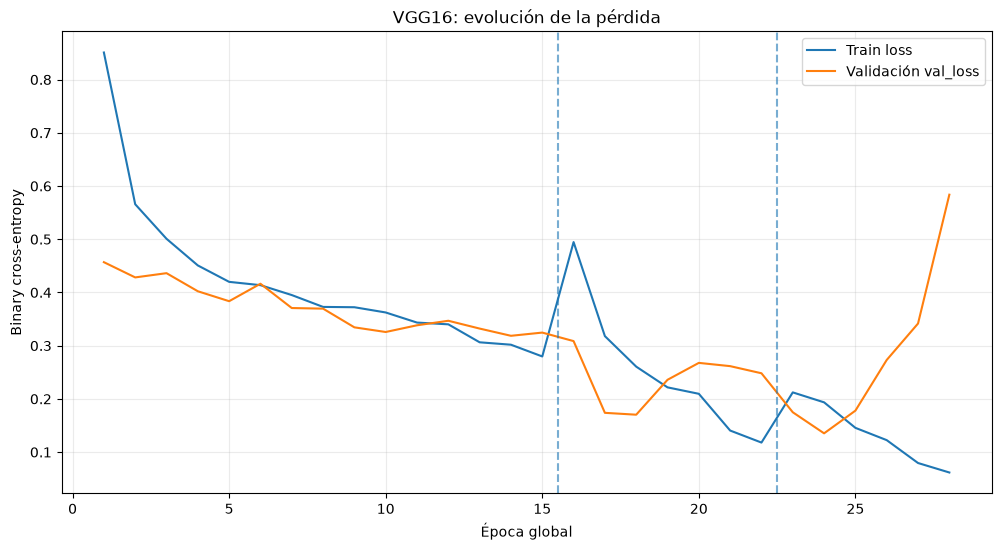

In [ ]:
plot_training_metric(
    train_metric="loss",
    validation_metric="val_loss",
    title="VGG16: evolución de la pérdida",
    ylabel="Binary cross-entropy"
)


Precisión

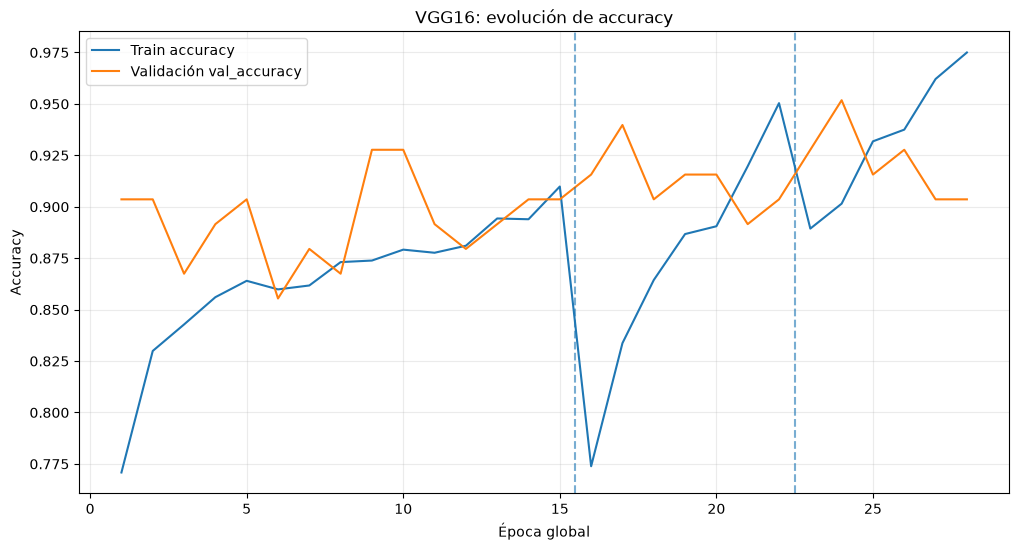

In [ ]:
plot_training_metric(
    train_metric="accuracy",
    validation_metric="val_accuracy",
    title="VGG16: evolución de accuracy",
    ylabel="Accuracy"
)

# AUC ROC

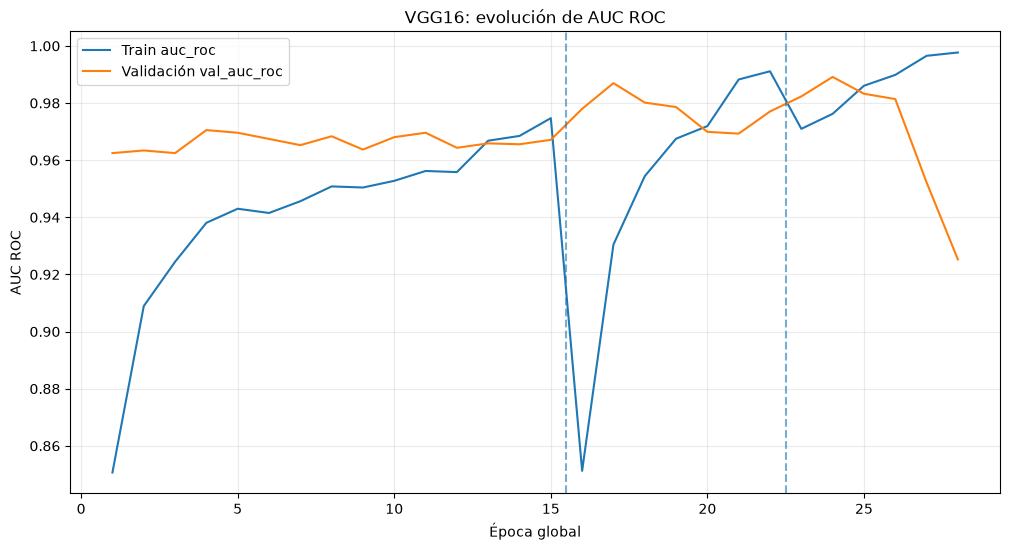

In [ ]:
plot_training_metric(
    train_metric="auc_roc",
    validation_metric="val_auc_roc",
    title="VGG16: evolución de AUC ROC",
    ylabel="AUC ROC"
)

# recall de validación

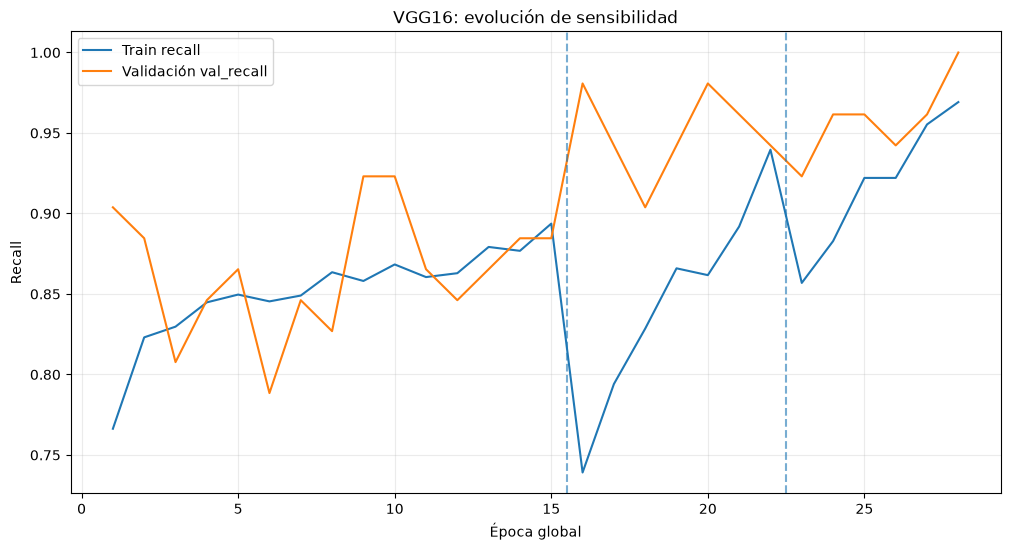

In [ ]:
plot_training_metric(
    train_metric="recall",
    validation_metric="val_recall",
    title="VGG16: evolución de sensibilidad",
    ylabel="Recall"
)

# Evaluacioón sobre validación original
Usaré inicialmente el umbral fijo 0.5.

In [ ]:
y_val = (
    val_df["binary_label"]
    .astype(int)
    .values
)

val_probabilities = (
    model.predict(
        val_ds,
        verbose=1
    )
    .reshape(-1)
)

VALIDATION_THRESHOLD = 0.5

val_predictions = (
    val_probabilities >= VALIDATION_THRESHOLD
).astype(int)

6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 844ms/step                                   


In [ ]:
val_auc_roc = roc_auc_score(
    y_val,
    val_probabilities
)

val_auc_pr = average_precision_score(
    y_val,
    val_probabilities
)

cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

sensitivity = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

accuracy = (
    (tp + tn) / cm.sum()
)

print(f"Accuracy:      {accuracy:.4f}")
print(f"Sensibilidad:  {sensitivity:.4f}")
print(f"Especificidad: {specificity:.4f}")
print(f"AUC ROC:       {val_auc_roc:.4f}")
print(f"AUC PR:        {val_auc_pr:.4f}")

print(
    classification_report(
        y_val,
        val_predictions,
        target_names=[
            "No referible",
            "Referible"
        ],
        digits=4,
        zero_division=0
    )
)

Accuracy:      0.9518
Sensibilidad:  0.9615
Especificidad: 0.9355
AUC ROC:       0.9895
AUC PR:        0.9944
              precision    recall  f1-score   support

No referible     0.9355    0.9355    0.9355        31
   Referible     0.9615    0.9615    0.9615        52

    accuracy                         0.9518        83
   macro avg     0.9485    0.9485    0.9485        83
weighted avg     0.9518    0.9518    0.9518        83



#Matriz de Confusión

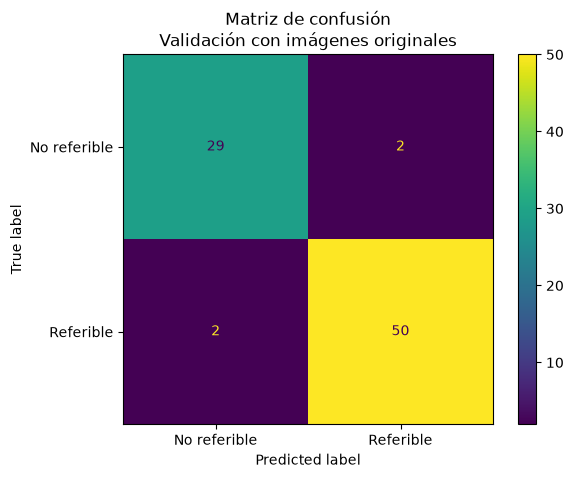

In [ ]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No referible",
        "Referible"
    ]
).plot(
    values_format="d"
)

plt.title(
    "Matriz de confusión\n"
    "Validación con imágenes originales"
)

plt.show()

# Curva ROC

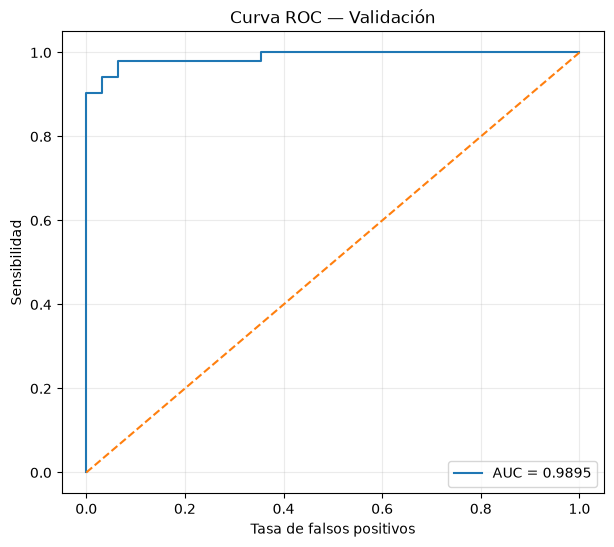

In [ ]:
fpr, tpr, _ = roc_curve(
    y_val,
    val_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {val_auc_roc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Sensibilidad")
plt.title("Curva ROC — Validación")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# Grad-CAM



In [ ]:
LAST_CONV_LAYER_NAME = "block5_conv3"


def load_image_for_gradcam(image_path):
    image = keras.utils.load_img(image_path)
    image_array = keras.utils.img_to_array(image)

    resized = tf.image.resize_with_pad(
        image_array,
        target_height=IMG_HEIGHT,
        target_width=IMG_WIDTH,
        antialias=True
    )

    display_image = np.clip(
        resized.numpy(),
        0,
        255
    ).astype(np.uint8)

    model_input = preprocess_input(
        tf.expand_dims(
            tf.cast(resized, tf.float32),
            axis=0
        )
    )

    return display_image, model_input

In [ ]:
def make_gradcam_heatmap(
    model_input,
    current_model,
    last_conv_layer_name,
    threshold=0.5
):
    last_conv_layer = current_model.get_layer(
        last_conv_layer_name
    )

    grad_model = keras.Model(
        inputs=current_model.inputs,
        outputs=[
            last_conv_layer.output,
            current_model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            model_input,
            training=False
        )

        probability = predictions[:, 0]

        predicted_class = tf.cast(
            probability >= threshold,
            tf.int32
        )

        target_score = tf.where(
            predicted_class == 1,
            probability,
            1.0 - probability
        )

    gradients = tape.gradient(
        target_score,
        conv_outputs
    )

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    maximum = tf.reduce_max(heatmap)

    heatmap = tf.where(
        maximum > 0,
        heatmap / maximum,
        heatmap
    )

    return (
        heatmap.numpy(),
        float(probability[0].numpy()),
        int(predicted_class[0].numpy())
    )

In [ ]:
def show_gradcam(
    image_path,
    true_label,
    current_model,
    threshold=0.5,
    title=None,
    alpha=0.40
):
    display_image, model_input = (
        load_image_for_gradcam(image_path)
    )

    heatmap, probability, predicted_class = (
        make_gradcam_heatmap(
            model_input=model_input,
            current_model=current_model,
            last_conv_layer_name=LAST_CONV_LAYER_NAME,
            threshold=threshold
        )
    )

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        size=(IMG_HEIGHT, IMG_WIDTH)
    ).numpy().squeeze()

    colored_heatmap = plt.colormaps["jet"](
        heatmap_resized
    )[..., :3]

    normalized_image = (
        display_image.astype(np.float16) / 255.0
    )

    overlay = np.clip(
        (1 - alpha) * normalized_image +
        alpha * colored_heatmap,
        0,
        1
    )

    true_name = CLASS_NAMES[int(true_label)]
    predicted_name = CLASS_NAMES[predicted_class]

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(display_image)
    plt.title("Imagen original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(
        heatmap_resized,
        cmap="jet"
    )
    plt.title("Mapa Grad-CAM")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(
        f"Real: {true_name}\n"
        f"Predicción: {predicted_name}\n"
        f"P(referible): {probability:.4f}"
    )
    plt.axis("off")

    if title:
        plt.suptitle(title)

    plt.tight_layout()
    plt.show()

# Analizar TP, TN, FP y FN con Grad-CAM

In [ ]:
results_df = val_df[
    [
        "Image name",
        "patient_id",
        "image_path",
        "binary_label"
    ]
].copy()

results_df["probability"] = val_probabilities
results_df["predicted_label"] = val_predictions

conditions = [
    (
        (results_df["binary_label"] == 1) &
        (results_df["predicted_label"] == 1)
    ),
    (
        (results_df["binary_label"] == 0) &
        (results_df["predicted_label"] == 0)
    ),
    (
        (results_df["binary_label"] == 0) &
        (results_df["predicted_label"] == 1)
    ),
    (
        (results_df["binary_label"] == 1) &
        (results_df["predicted_label"] == 0)
    )
]

results_df["case_type"] = np.select(
    conditions,
    ["TP", "TN", "FP", "FN"],
    default="Otro"
)

display(
    results_df["case_type"]
    .value_counts()
)

NameError: name 'val_df' is not defined

In [ ]:
for case_type in ["TP", "TN", "FP", "FN"]:
    candidates = results_df[
        results_df["case_type"] == case_type
    ]

    if candidates.empty:
        print(
            f"No existen casos {case_type}."
        )
        continue

    if case_type in ["TP", "FP"]:
        selected = candidates.sort_values(
            "probability",
            ascending=False
        ).iloc[0]
    else:
        selected = candidates.sort_values(
            "probability",
            ascending=True
        ).iloc[0]

    show_gradcam(
        image_path=selected["image_path"],
        true_label=selected["binary_label"],
        current_model=model,
        threshold=VALIDATION_THRESHOLD,
        title=(
            f"Grad-CAM — {case_type} — "
            f'{selected["Image name"]}'
        )
    )

ValueError: No such layer: block5_conv3. Existing layers are: ['input_layer_2', 'vgg16', 'global_average_pooling2d', 'dense', 'dropout', 'dense_1'].

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras


LAST_CONV_LAYER_NAME = "block5_conv3"


def make_gradcam_heatmap(
    model_input,
    current_model,
    last_conv_layer_name="block5_conv3",
):
    # Backbone VGG16
    backbone = current_model.get_layer("vgg16")

    # Última capa convolucional
    last_conv_layer = backbone.get_layer(last_conv_layer_name)

    # Modelo que entrega activaciones de block5_conv3
    conv_model = keras.Model(
        inputs=backbone.input,
        outputs=last_conv_layer.output,
    )

    # Reconstruir el resto del modelo desde block5_conv3
    classifier_input = keras.Input(
        shape=last_conv_layer.output.shape[1:]
    )

    x = classifier_input

    start_passing = False

    for layer in backbone.layers:
        if layer.name == last_conv_layer_name:
            start_passing = True
            continue

        if start_passing:
            x = layer(x)

    backbone_found = False

    for layer in current_model.layers:
        if layer.name == backbone.name:
            backbone_found = True
            continue

        if backbone_found:
            x = layer(x)

    classifier_model = keras.Model(
        classifier_input,
        x,
    )

    # Gradientes
    with tf.GradientTape() as tape:
        conv_outputs = conv_model(model_input)
        tape.watch(conv_outputs)

        predictions = classifier_model(conv_outputs)

        # Salida sigmoid binaria
        class_score = predictions[:, 0]

    grads = tape.gradient(
        class_score,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(heatmap, 0)

    # Normalización
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap = heatmap / max_value

    probability = float(
        predictions[0, 0].numpy()
    )

    return heatmap.numpy(), probability

In [ ]:
vgg_backbone = model.get_layer("vgg16")

print("=== CAPAS FINALES DE VGG16 ===")
for layer in vgg_backbone.layers[-10:]:
    print(layer.name)

=== CAPAS FINALES DE VGG16 ===
block3_conv3
block3_pool
block4_conv1
block4_conv2
block4_conv3
block4_pool
block5_conv1
block5_conv2
block5_conv3
block5_pool


In [ ]:
def make_gradcam_heatmap(
    model_input,
    current_model,
    last_conv_layer_name,
):
    # ============================================================
    # 1. Localizar el backbone VGG16
    # ============================================================
    try:
        backbone = current_model.get_layer("vgg16")
    except ValueError:
        raise ValueError(
            "No se encontró una capa llamada 'vgg16' dentro del modelo."
        )

    # ============================================================
    # 2. Localizar la última capa convolucional DENTRO de VGG16
    # ============================================================
    try:
        last_conv_layer = backbone.get_layer(last_conv_layer_name)
    except ValueError:
        raise ValueError(
            f"No se encontró la capa '{last_conv_layer_name}' "
            f"dentro de VGG16."
        )

    # ============================================================
    # 3. Modelo para obtener activaciones de block5_conv3
    # ============================================================
    conv_model = tf.keras.Model(
        inputs=backbone.input,
        outputs=last_conv_layer.output,
    )

    # ============================================================
    # 4. Modelo correspondiente al clasificador
    # ============================================================
    classifier_input = tf.keras.Input(
        shape=last_conv_layer.output.shape[1:]
    )

    x = classifier_input

    # block5_conv3 todavía pasa por block5_pool
    start_passing = False

    for layer in backbone.layers:
        if layer.name == last_conv_layer_name:
            start_passing = True
            continue

        if start_passing:
            x = layer(x)

    # Capas externas posteriores a VGG16
    backbone_found = False

    for layer in current_model.layers:
        if layer.name == backbone.name:
            backbone_found = True
            continue

        if backbone_found:
            x = layer(x)

    classifier_model = tf.keras.Model(
        classifier_input,
        x,
    )

    # ============================================================
    # 5. Grad-CAM
    # ============================================================
    with tf.GradientTape() as tape:

        conv_outputs = conv_model(model_input)

        tape.watch(conv_outputs)

        predictions = classifier_model(conv_outputs)

        # Modelo binario con salida sigmoid
        probability = predictions[:, 0]

    grads = tape.gradient(
        probability,
        conv_outputs,
    )

    if grads is None:
        raise RuntimeError(
            "No fue posible calcular los gradientes para Grad-CAM."
        )

    # ============================================================
    # 6. Promedio espacial de gradientes
    # ============================================================
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2),
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1,
    )

    # ============================================================
    # 7. ReLU + normalización
    # ============================================================
    heatmap = tf.maximum(
        heatmap,
        0,
    )

    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap = heatmap / max_value

    heatmap = heatmap.numpy()

    # ============================================================
    # 8. Probabilidad y clase predicha
    # ============================================================
    probability_value = float(
        predictions[0, 0].numpy()
    )

    predicted_class = int(
        probability_value >= 0.5
    )

    return (
        heatmap,
        probability_value,
        predicted_class,
    )

In [ ]:
def show_gradcam(
    image_path,
    true_label,
    current_model,
    threshold=0.5,
    title=None,
):
    # ============================================================
    # CARGAR IMAGEN
    # ============================================================
    img = keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    img_array = keras.utils.img_to_array(img)

    # Guardamos versión original para visualizar
    original_image = img_array.astype("uint8")

    # Batch
    model_input = np.expand_dims(
        img_array,
        axis=0
    )

    # ============================================================
    # CALCULAR GRAD-CAM
    # ============================================================
    heatmap, probability = make_gradcam_heatmap(
        model_input=model_input,
        current_model=current_model,
        last_conv_layer_name=LAST_CONV_LAYER_NAME,
    )

    predicted_class = int(
        probability >= threshold
    )

    # ============================================================
    # REDIMENSIONAR HEATMAP
    # ============================================================
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        IMG_SIZE
    ).numpy().squeeze()

    # ============================================================
    # CREAR MAPA DE COLOR
    # ============================================================
    cmap = plt.get_cmap("jet")

    heatmap_colored = cmap(
        heatmap_resized
    )[..., :3]

    heatmap_colored = (
        heatmap_colored * 255
    ).astype("uint8")

    # ============================================================
    # SUPERPONER SOBRE IMAGEN
    # ============================================================
    alpha = 0.40

    superimposed = (
        original_image * (1 - alpha)
        + heatmap_colored * alpha
    )

    superimposed = np.clip(
        superimposed,
        0,
        255
    ).astype("uint8")

    # ============================================================
    # MOSTRAR RESULTADOS
    # ============================================================
    plt.figure(figsize=(15, 5))

    # Imagen original
    plt.subplot(1, 3, 1)
    plt.imshow(original_image)
    plt.title("Imagen original")
    plt.axis("off")

    # Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(
        heatmap_resized,
        cmap="jet"
    )
    plt.title("Grad-CAM")
    plt.axis("off")

    # Superposición
    plt.subplot(1, 3, 3)
    plt.imshow(superimposed)

    plt.title(
        f"Superposición\n"
        f"Real: {true_label} | "
        f"Pred: {predicted_class} | "
        f"P={probability:.3f}"
    )

    plt.axis("off")

    if title is not None:
        plt.suptitle(
            title,
            fontsize=14,
            fontweight="bold"
        )

    plt.tight_layout()
    plt.show()

# Cargar el modelo sin volver a entrenar

Ejecuta esta sección en una sesión donde `FINAL_MODEL_PATH` apunte al archivo `.keras` guardado. Para conservar el modelo entre reinicios de Colab, copia el archivo final a Google Drive al terminar el entrenamiento.


In [ ]:
import tensorflow as tf

# Cargar el modelo guardado
model = tf.keras.models.load_model(FINAL_MODEL_PATH)

print(f"Modelo cargado exitosamente desde: {FINAL_MODEL_PATH}")


## Predicción con nuevas imágenes

Para predecir con imágenes no vistas, necesitamos un manifiesto con los nombres de las imágenes y sus rutas, similar a como preparamos los datos de entrenamiento y validación.

In [ ]:
# Crea una carpeta de ejemplo para nuevas imágenes.
# En un caso real, estas serían tus nuevas imágenes.
NEW_IMAGES_DIR = Path("/data/IDRiD2/IDRiD/test/images")
NEW_IMAGES_DIR.mkdir(parents=True, exist_ok=True)

# Simulamos algunas imágenes nuevas copiando algunas del conjunto de entrenamiento
# para tener archivos reales con los que trabajar.
# En la práctica, aquí cargarías tus propias imágenes.

# Obtener algunas rutas de imágenes de ejemplo del conjunto de entrenamiento
example_image_paths = train_df["image_path"].sample(5, random_state=SEED).tolist()

new_image_names = []
new_image_full_paths = []

for i, src_path in enumerate(example_image_paths):
    img_name = f"new_test_image_{i}.jpg"
    dest_path = NEW_IMAGES_DIR / img_name
    shutil.copy(src_path, dest_path)
    new_image_names.append(dest_path.stem) # Solo el nombre base sin extensión
    new_image_full_paths.append(str(dest_path))

print(f"Se han simulado {len(new_image_names)} nuevas imágenes en: {NEW_IMAGES_DIR}")

# Crear un DataFrame dummy para estas nuevas imágenes.
# Necesitamos 'Image name' para el mapeo y 'binary_label' como un placeholder.
# La etiqueta binaria no importa para la predicción, pero la función make_dataset la espera.
new_images_df = pd.DataFrame({
    "Image name": new_image_names,
    "binary_label": 0, # Placeholder
    "patient_id": new_image_names # Usar el nombre como patient_id temporal
})

# Asignar las rutas reales de las imágenes a este DataFrame
new_images_df["image_path"] = new_image_full_paths

display(new_images_df.head())

Se han simulado 5 nuevas imágenes en: \content\data\IDRiD2\IDRiD\test\images


,Image name,binary_label,patient_id,image_path
0,new_test_image_0,0,new_test_image_0,\content\data\IDRiD2\IDRiD\test\images\new_tes...
1,new_test_image_1,0,new_test_image_1,\content\data\IDRiD2\IDRiD\test\images\new_tes...
2,new_test_image_2,0,new_test_image_2,\content\data\IDRiD2\IDRiD\test\images\new_tes...
3,new_test_image_3,0,new_test_image_3,\content\data\IDRiD2\IDRiD\test\images\new_tes...
4,new_test_image_4,0,new_test_image_4,\content\data\IDRiD2\IDRiD\test\images\new_tes...


Ahora, creamos un `tf.data.Dataset` para estas nuevas imágenes usando la misma función `make_dataset` que usamos para la validación.

In [ ]:
new_test_ds = make_dataset(
    new_images_df,
    training=False,
    cache=False,
    dataset_name="new_test"
)

print(f"Dataset para nuevas imágenes creado con {len(new_images_df)} elementos.")


new_test: 5 imágenes | batch=16 | caché=none | estimación=0.00 GiB
Dataset para nuevas imágenes creado con 5 elementos.


Finalmente, utilizamos el modelo cargado para hacer las predicciones.

In [ ]:
# Asegúrate de que el modelo esté cargado desde la mejor fase de entrenamiento
# (Esto ya se hizo en una celda anterior, pero es una buena práctica verificar)
# if 'model' not in locals() or not isinstance(model, keras.Model):
#     model = keras.models.load_model(FINAL_MODEL_PATH)

print("Realizando predicciones en las nuevas imágenes...")
new_predictions = model.predict(new_test_ds, verbose=1).reshape(-1)

# Añadir las predicciones al DataFrame de nuevas imágenes
new_images_df["predicted_probability"] = new_predictions
new_images_df["predicted_label"] = (new_predictions >= VALIDATION_THRESHOLD).astype(int)

# Mapear las etiquetas predichas a sus nombres
new_images_df["predicted_class_name"] = new_images_df["predicted_label"].map(CLASS_NAMES)

print("Predicciones completadas.")
display(new_images_df[['Image name', 'predicted_probability', 'predicted_class_name']].head())

Realizando predicciones en las nuevas imágenes...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 923ms/step                                                                                                                                                                                                                                                                                                            
Predicciones completadas.


,Image name,predicted_probability,predicted_class_name
0,new_test_image_0,1.000000,Referible
1,new_test_image_1,0.987026,Referible
2,new_test_image_2,0.999998,Referible
3,new_test_image_3,0.097654,No referible
4,new_test_image_4,1.000000,Referible


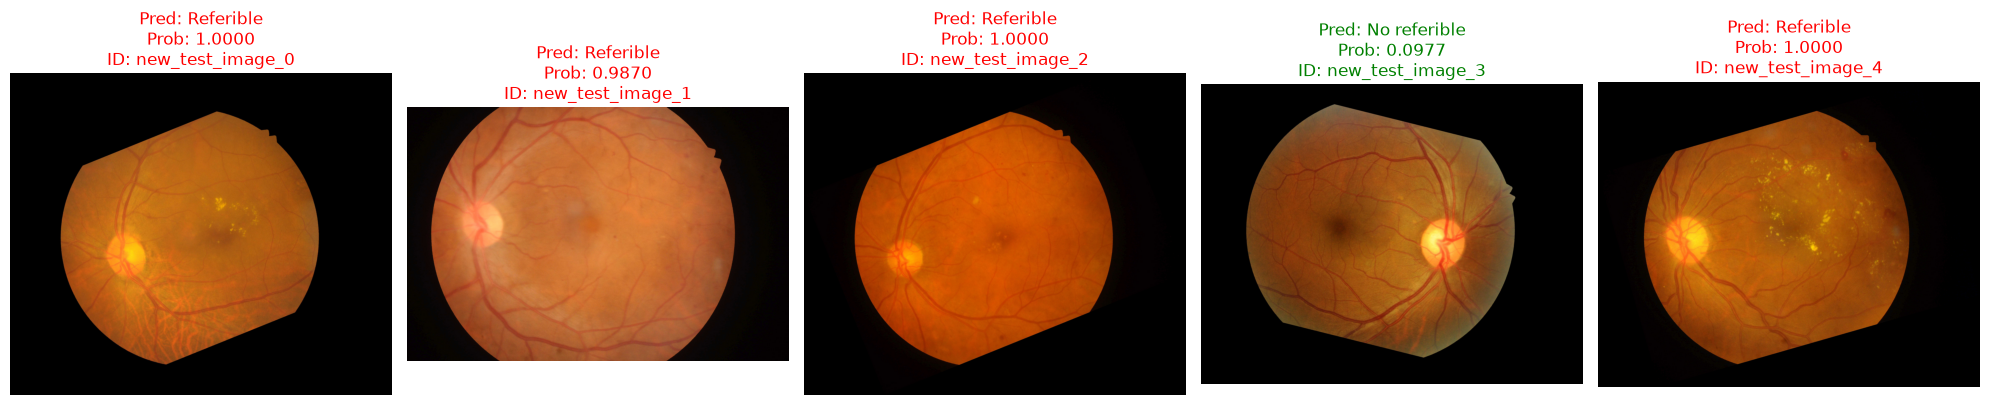

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

def plot_new_predictions(df, n_images=5):
    plt.figure(figsize=(20, 10))

    # Tomamos una muestra o las primeras n imágenes
    sample_df = df.head(n_images)

    for i, (_, row) in enumerate(sample_df.iterrows()):
        # Cargar y decodificar la imagen para visualización
        img = tf.keras.utils.load_img(row['image_path'])

        plt.subplot(1, n_images, i + 1)
        plt.imshow(img)

        color = 'green' if row['predicted_label'] == 0 else 'red'

        title = (f"Pred: {row['predicted_class_name']}\n"
                 f"Prob: {row['predicted_probability']:.4f}\n"
                 f"ID: {row['Image name']}")

        plt.title(title, color=color, fontsize=12)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Ejecutamos la función con el DataFrame de nuevas imágenes
plot_new_predictions(new_images_df)

### Predicciones sobre el Set de Pruebas Original (Test Set)
Ahora utilizaremos la carpeta oficial de pruebas del dataset para evaluar el modelo.

Imágenes de prueba encontradas: 5
test_set_eval: 5 imágenes | batch=16 | caché=none | estimación=0.00 GiB
Procesando predicciones del set de prueba...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 700ms/step                                                                                                                                                                                                                                                                                                            


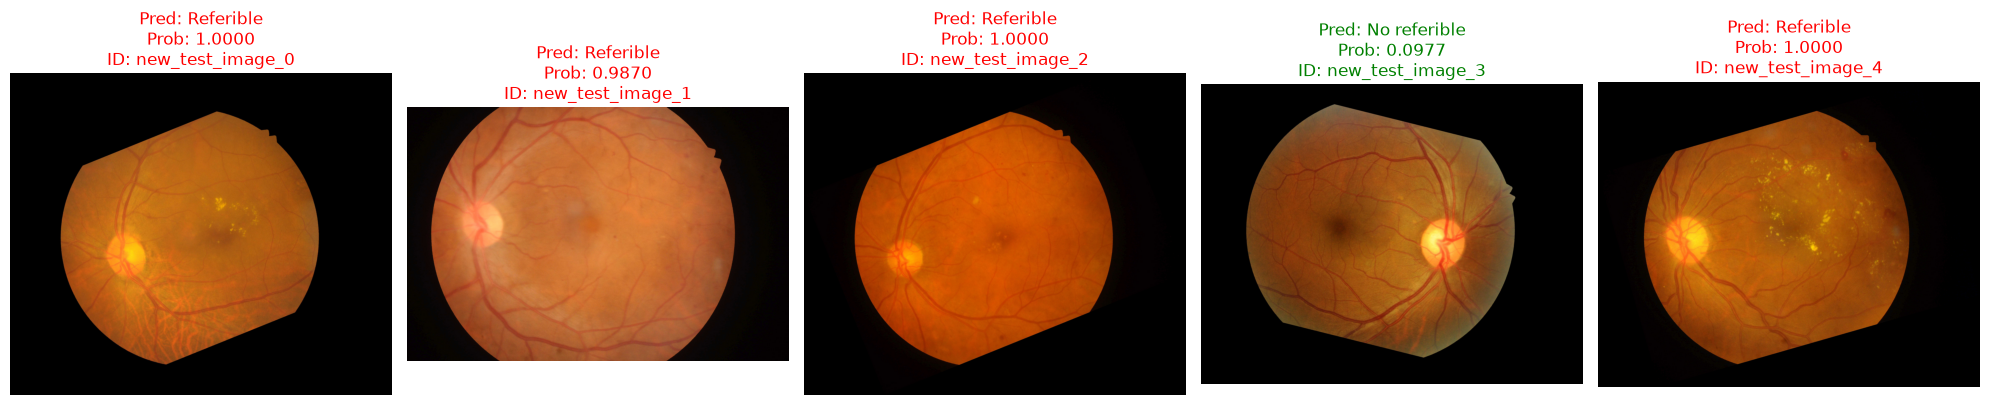

,Image name,predicted_probability,predicted_class_name
0,new_test_image_0,1.000000,Referible
1,new_test_image_1,0.987026,Referible
2,new_test_image_2,0.999998,Referible
3,new_test_image_3,0.097654,No referible
4,new_test_image_4,1.000000,Referible


In [ ]:
# 1. Definir ruta y buscar imágenes de prueba reales
TEST_IMAGES_DIR = Path("/content/data/IDRiD2/IDRiD/test/images")

# Reutilizamos la lógica de indexación para el set de test
test_image_index = build_image_index([TEST_IMAGES_DIR])

# 2. Crear el DataFrame de pruebas
test_images_df = pd.DataFrame({
    "Image name": list(test_image_index.keys()),
    "image_path": list(test_image_index.values()),
    "binary_label": 0  # Placeholder
})

print(f"Imágenes de prueba encontradas: {len(test_images_df)}")

# 3. Crear el Dataset de TensorFlow
test_ds = make_dataset(
    test_images_df,
    training=False,
    cache=False,
    dataset_name="test_set_eval"
)

# 4. Ejecutar predicciones
print("Procesando predicciones del set de prueba...")
test_probs = model.predict(test_ds, verbose=1).reshape(-1)

# 5. Consolidar resultados
test_images_df["predicted_probability"] = test_probs
test_images_df["predicted_label"] = (test_probs >= VALIDATION_THRESHOLD).astype(int)
test_images_df["predicted_class_name"] = test_images_df["predicted_label"].map(CLASS_NAMES)

# 6. Mostrar resultados visuales (una muestra de 5)
plot_new_predictions(test_images_df, n_images=5)

display(test_images_df[['Image name', 'predicted_probability', 'predicted_class_name']].head(10))

Puedes ajustar la variable `NEW_IMAGES_DIR` y el proceso de creación de `new_images_df` para apuntar a tus propias imágenes reales. La columna `binary_label` en `new_images_df` solo es un marcador de posición y no afecta las predicciones.

In [ ]:
# 1. Solicitar la ruta de la imagen al usuario
image_path_input = input("Introduce la ruta completa de la imagen (ej: /content/data/IDRiD2/IDRiD/test/images/IDRiD_001.jpg): ")

if os.path.exists(image_path_input):
    # 2. Cargar y preprocesar la imagen
    # Usamos load_img para visualización y luego la procesamos para el modelo
    img_display = keras.utils.load_img(image_path_input)

    # Preprocesamiento manual siguiendo la lógica de decode_and_resize
    img_bytes = tf.io.read_file(image_path_input)
    img_tensor = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
    img_tensor = tf.cast(img_tensor, tf.float32)
    img_tensor = tf.image.resize_with_pad(img_tensor, target_height=IMG_HEIGHT, target_width=IMG_WIDTH)

    # Aplicar el preprocesamiento específico de VGG16 y añadir dimensión de batch
    model_input = preprocess_input(tf.expand_dims(img_tensor, axis=0))

    # 3. Realizar la predicción
    prediction_prob = model.predict(model_input, verbose=0)[0][0]
    predicted_label = int(prediction_prob >= VALIDATION_THRESHOLD)
    class_name = CLASS_NAMES[predicted_label]

    # 4. Graficar el resultado
    plt.figure(figsize=(6, 6))
    plt.imshow(img_display)

    color = 'red' if predicted_label == 1 else 'green'
    plt.title(f"Resultado: {class_name}\nProbabilidad: {prediction_prob:.4f}",
              color=color, fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()
else:
    print("Error: La ruta especificada no existe. Por favor, verifica la ruta en el panel lateral de archivos.")

Error: La ruta especificada no existe. Por favor, verifica la ruta en el panel lateral de archivos.


In [ ]:
# @title 📊 Dashboard de Métricas de Entrenamiento {display-mode: "form"}
import json
import pandas as pd
from IPython.display import display, HTML
from google.colab import output

def _report_js_error(message):
    print(f"JavaScript Error: {message}")

output.register_callback('report_js_error', _report_js_error)

# Preparar datos del DataFrame history_df
if 'history_df' in globals():
    safe_df = history_df.fillna(0)
    hist_data = safe_df.to_dict(orient='records')
    best_epoch = safe_df.loc[safe_df['val_loss'].idxmin()] if not safe_df.empty else None
else:
    hist_data = []
    best_epoch = None

kpi_data = {
    'best_val_loss': float(best_epoch['val_loss']) if best_epoch is not None else 0.0,
    'best_val_acc': float(best_epoch['val_accuracy']) if best_epoch is not None else 0.0,
    'best_val_auc': float(best_epoch['val_auc_roc']) if best_epoch is not None else 0.0,
    'total_epochs': len(hist_data)
}

html_template = """
<!DOCTYPE html>
<html>
<head>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <style>
        :root {
            --bg: #f4f6f8;
            --card-bg: #ffffff;
            --text: #333333;
            --text-muted: #666666;
            --border: #e0e0e0;
            --primary: #4361ee;
            --secondary: #3f37c9;
            --success: #4cc9f0;
            --danger: #f72585;
        }
        body { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; background: var(--bg); color: var(--text); margin: 0; padding: 20px; }
        .dashboard { display: flex; flex-direction: column; gap: 20px; }
        .kpi-row { display: grid; grid-template-columns: repeat(auto-fit, minmax(200px, 1fr)); gap: 20px; }
        .kpi-card { background: var(--card-bg); padding: 20px; border-radius: 10px; box-shadow: 0 4px 6px rgba(0,0,0,0.05); text-align: center; }
        .kpi-value { font-size: 2em; font-weight: bold; color: var(--primary); margin: 10px 0; }
        .kpi-label { font-size: 0.9em; color: var(--text-muted); text-transform: uppercase; letter-spacing: 1px; }
        .charts-row { display: grid; grid-template-columns: 1fr 1fr; gap: 20px; }
        @media (max-width: 900px) { .charts-row { grid-template-columns: 1fr; } }
        .chart-card { background: var(--card-bg); padding: 20px; border-radius: 10px; box-shadow: 0 4px 6px rgba(0,0,0,0.05); display: flex; flex-direction: column; min-height: 350px; }
        .chart-title { font-size: 1.2em; font-weight: 600; margin-bottom: 15px; color: var(--text); }
        .canvas-wrapper { position: relative; flex-grow: 1; min-height: 0; }
        .table-container { background: var(--card-bg); padding: 20px; border-radius: 10px; box-shadow: 0 4px 6px rgba(0,0,0,0.05); overflow-x: auto; max-height: 400px; }
        table { width: 100%; border-collapse: collapse; }
        th, td { padding: 12px; text-align: left; border-bottom: 1px solid var(--border); }
        th { background: var(--bg); font-weight: 600; color: var(--text-muted); position: sticky; top: 0; }
        tr:hover { background: #f8f9fa; }
    </style>
</head>
<body>
    <div class="dashboard">
        <div class="kpi-row">
            <div class="kpi-card"><div class="kpi-label">Mejor Pérdida (Val)</div><div class="kpi-value" id="kpi-loss">--</div></div>
            <div class="kpi-card"><div class="kpi-label">Mejor Exactitud (Val)</div><div class="kpi-value" id="kpi-acc">--</div></div>
            <div class="kpi-card"><div class="kpi-label">Mejor AUC ROC (Val)</div><div class="kpi-value" id="kpi-auc">--</div></div>
            <div class="kpi-card"><div class="kpi-label">Total de Épocas</div><div class="kpi-value" id="kpi-epochs">--</div></div>
        </div>
        <div class="charts-row">
            <div class="chart-card">
                <div class="chart-title">Evolución de Pérdida (Loss)</div>
                <div class="canvas-wrapper"><canvas id="lossChart"></canvas></div>
            </div>
            <div class="chart-card">
                <div class="chart-title">Evolución de AUC ROC</div>
                <div class="canvas-wrapper"><canvas id="aucChart"></canvas></div>
            </div>
        </div>
        <div class="table-container">
            <div class="chart-title">Detalle por Época</div>
            <table>
                <thead>
                    <tr><th>Época Global</th><th>Fase</th><th>Loss</th><th>Val Loss</th><th>Accuracy</th><th>Val Accuracy</th><th>Val AUC</th></tr>
                </thead>
                <tbody id="table-body"></tbody>
            </table>
        </div>
    </div>
    <script>
        window.onerror = function(message) {
            google.colab.kernel.invokeFunction('report_js_error', [message], {});
        };

        const histData = DATA_PLACEHOLDER;
        const kpiData = KPI_PLACEHOLDER;

        document.getElementById('kpi-loss').innerText = kpiData.best_val_loss.toFixed(4);
        document.getElementById('kpi-acc').innerText = (kpiData.best_val_acc * 100).toFixed(2) + '%';
        document.getElementById('kpi-auc').innerText = kpiData.best_val_auc.toFixed(4);
        document.getElementById('kpi-epochs').innerText = kpiData.total_epochs;

        const labels = histData.map(d => d.global_epoch);
        const lossTrain = histData.map(d => d.loss);
        const lossVal = histData.map(d => d.val_loss);
        const aucTrain = histData.map(d => d.auc_roc);
        const aucVal = histData.map(d => d.val_auc_roc);

        const commonOptions = {
            responsive: true,
            maintainAspectRatio: false,
            interaction: { mode: 'index', intersect: false },
            plugins: { legend: { position: 'bottom' } }
        };

        new Chart(document.getElementById('lossChart'), {
            type: 'line',
            data: {
                labels: labels,
                datasets: [
                    { label: 'Train Loss', data: lossTrain, borderColor: '#4cc9f0', backgroundColor: 'rgba(76, 201, 240, 0.1)', fill: true, tension: 0.3 },
                    { label: 'Val Loss', data: lossVal, borderColor: '#f72585', backgroundColor: 'rgba(247, 37, 133, 0.1)', fill: true, tension: 0.3 }
                ]
            },
            options: commonOptions
        });

        new Chart(document.getElementById('aucChart'), {
            type: 'line',
            data: {
                labels: labels,
                datasets: [
                    { label: 'Train AUC', data: aucTrain, borderColor: '#4361ee', tension: 0.3 },
                    { label: 'Val AUC', data: aucVal, borderColor: '#3f37c9', tension: 0.3 }
                ]
            },
            options: commonOptions
        });

        const tbody = document.getElementById('table-body');
        histData.forEach(d => {
            const tr = document.createElement('tr');
            tr.innerHTML = `
                <td>${d.global_epoch || '-'}</td>
                <td>${d.phase || '-'}</td>
                <td>${d.loss ? d.loss.toFixed(4) : '-'}</td>
                <td>${d.val_loss ? d.val_loss.toFixed(4) : '-'}</td>
                <td>${d.accuracy ? (d.accuracy * 100).toFixed(2) + '%' : '-'}</td>
                <td>${d.val_accuracy ? (d.val_accuracy * 100).toFixed(2) + '%' : '-'}</td>
                <td>${d.val_auc_roc ? d.val_auc_roc.toFixed(4) : '-'}</td>
            `;
            tbody.appendChild(tr);
        });
    </script>
</body>
</html>
"""

html_content = html_template.replace('DATA_PLACEHOLDER', json.dumps(hist_data)).replace('KPI_PLACEHOLDER', json.dumps(kpi_data))
display(HTML(html_content))


ModuleNotFoundError: No module named 'google.colab'